# PRCP-1000: Portuguese Bank Marketing Prediction

## Project Overview
This project analyzes a Portuguese bank's direct marketing campaign
and develops machine learning models to predict whether a customer
will subscribe to a term deposit.

## Objectives
1. Perform comprehensive exploratory data analysis.
2. Identify factors influencing term deposit subscriptions.
3. Build and compare multiple classification models.
4. Select a suitable model for production.
5. Provide practical marketing recommendations.
6. Document data challenges and solutions.

## Dataset
Bank Marketing Dataset:
bank-additional-full.csv

## Target Variable
y: Whether the customer subscribed to a term deposit (yes/no).

## Important Modeling Note
The duration feature will be excluded from the production model
because it is only known after the call has taken place.

In [2]:
from pathlib import Path

# Common locations where the dataset may be stored
search_locations = [
    Path.cwd(),
    Path.home() / "Downloads",
    Path.home() / "Desktop"
]

dataset_files = []

for location in search_locations:
    if location.exists():
        dataset_files.extend(
            location.rglob("bank-additional-full.csv")
        )

# Remove duplicate paths
dataset_files = list(set(dataset_files))

print("Current working directory:")
print(Path.cwd())

print("\nDataset files found:")

if dataset_files:
    for i, file_path in enumerate(dataset_files, start=1):
        print(f"{i}. {file_path}")
else:
    print("Dataset not found.")
    print("Please extract the ZIP and place the CSV in your project folder.")
    

Current working directory:
C:\Users\prana\Project For ML\PRCP-1000-PortugeseBank

Dataset files found:
1. C:\Users\prana\Downloads\PRCP-1000-ProtugeseBank\Data\bank-additional\bank-additional-full.csv
2. C:\Users\prana\Project For ML\PRCP-1000-PortugeseBank\bank-additional\bank-additional-full.csv


## Step 2: Dataset Loading and Initial Inspection

In this section, we load the Portuguese Bank Marketing dataset
and inspect its dimensions, columns, data types, and sample records.

In [3]:
# Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings("ignore")

# Set visualization style
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

# Dataset path
data_path = r"C:\Users\prana\Project For ML\PRCP-1000-PortugeseBank\bank-additional\bank-additional-full.csv"

# Load dataset
df = pd.read_csv(data_path, sep=";")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

Dataset loaded successfully!
Dataset shape: (41188, 21)


In [4]:
# Display the first 5 rows
df.head()

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


In [5]:
#Check dataset dimensions

print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

print("\nColumn names:")
print(df.columns.tolist())

Number of rows: 41188
Number of columns: 21

Column names:
['age', 'job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed', 'y']


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  object 
 2   marital         41188 non-null  object 
 3   education       41188 non-null  object 
 4   default         41188 non-null  object 
 5   housing         41188 non-null  object 
 6   loan            41188 non-null  object 
 7   contact         41188 non-null  object 
 8   month           41188 non-null  object 
 9   day_of_week     41188 non-null  object 
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  object 
 15  emp.var.rate    41188 non-null  float64
 16  cons.price.idx  41188 non-null  float64
 17  cons.conf.idx   41188 non-null 

In [7]:
# Summary of numerical columns
display(df.describe().T)

# Summary of categorical columns
display(df.describe(include="object").T)

,count,mean,std,min,25%,50%,75%,max
age,41188.0,40.024060,10.421250,17.000,32.000,38.000,47.000,98.000
duration,41188.0,258.285010,259.279249,0.000,102.000,180.000,319.000,4918.000
campaign,41188.0,2.567593,2.770014,1.000,1.000,2.000,3.000,56.000
pdays,41188.0,962.475454,186.910907,0.000,999.000,999.000,999.000,999.000
previous,41188.0,0.172963,0.494901,0.000,0.000,0.000,0.000,7.000
emp.var.rate,41188.0,0.081886,1.570960,-3.400,-1.800,1.100,1.400,1.400
cons.price.idx,41188.0,93.575664,0.578840,92.201,93.075,93.749,93.994,94.767
cons.conf.idx,41188.0,-40.502600,4.628198,-50.800,-42.700,-41.800,-36.400,-26.900
euribor3m,41188.0,3.621291,1.734447,0.634,1.344,4.857,4.961,5.045
nr.employed,41188.0,5167.035911,72.251528,4963.600,5099.100,5191.000,5228.100,5228.100


,count,unique,top,freq
job,41188,12,admin.,10422
marital,41188,4,married,24928
education,41188,8,university.degree,12168
default,41188,3,no,32588
housing,41188,3,yes,21576
loan,41188,3,no,33950
contact,41188,2,cellular,26144
month,41188,10,may,13769
day_of_week,41188,5,thu,8623
poutcome,41188,3,nonexistent,35563


In [9]:
# Check missing values

missing_values = df.isnull().sum()

missing_summary = pd.DataFrame({
    "Missing Values": missing_values,
    "Missing Percentage": (
        missing_values / len(df) * 100
    ).round(2)
})

display(missing_summary)

,Missing Values,Missing Percentage
age,0,0.0
job,0,0.0
marital,0,0.0
education,0,0.0
default,0,0.0
housing,0,0.0
loan,0,0.0
contact,0,0.0
month,0,0.0
day_of_week,0,0.0


In [11]:
# Check duplicate records
duplicate_count = df.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)
print("Duplicate percentage:", round(
    duplicate_count / len(df) * 100, 2
), "%")

Number of duplicate rows: 12
Duplicate percentage: 0.03 %


## Step 3: Data Cleaning and Quality Checks

This section checks duplicate records, missing values,
unknown categorical values, and data consistency.

In [12]:
# Preserve original data
df_original = df.copy()

# Remove exact duplicate rows
df = df.drop_duplicates().reset_index(drop=True)

print("Original dataset shape:", df_original.shape)
print("Cleaned dataset shape:", df.shape)
print("Duplicates remaining:", df.duplicated().sum())

Original dataset shape: (41188, 21)
Cleaned dataset shape: (41176, 21)
Duplicates remaining: 0


In [13]:
# Check missing values
missing_values = df.isnull().sum()

missing_summary = pd.DataFrame({
    "Missing Values": missing_values,
    "Missing Percentage": (
        missing_values / len(df) * 100
    ).round(2)
})

display(missing_summary)

,Missing Values,Missing Percentage
age,0,0.0
job,0,0.0
marital,0,0.0
education,0,0.0
default,0,0.0
housing,0,0.0
loan,0,0.0
contact,0,0.0
month,0,0.0
day_of_week,0,0.0


In [14]:
# Check unknown values
# Count unknown values in each column
unknown_summary = {}

for column in df.select_dtypes(include="object").columns:
    unknown_count = (df[column] == "unknown").sum()

    if unknown_count > 0:
        unknown_summary[column] = unknown_count

unknown_df = pd.DataFrame(
    list(unknown_summary.items()),
    columns=["Column", "Unknown Count"]
)

if not unknown_df.empty:
    unknown_df["Percentage"] = (
        unknown_df["Unknown Count"] / len(df) * 100
    ).round(2)

display(unknown_df)

,Column,Unknown Count,Percentage
0,job,330,0.80
1,marital,80,0.19
2,education,1730,4.20
3,default,8596,20.88
4,housing,990,2.40
5,loan,990,2.40


In [15]:
# Check target variable
print("Target variable distribution:")
display(df["y"].value_counts())

print("\nTarget variable percentage:")
display(
    (df["y"].value_counts(normalize=True) * 100).round(2)
)

Target variable distribution:


y
no     36537
yes     4639
Name: count, dtype: int64


Target variable percentage:


y
no     88.73
yes    11.27
Name: proportion, dtype: float64

In [16]:
# Check unique values in categorical columns
for column in df.select_dtypes(include="object").columns:
    print(f"\n{column}:")
    print(df[column].unique())
    


job:
['housemaid' 'services' 'admin.' 'blue-collar' 'technician' 'retired'
 'management' 'unemployed' 'self-employed' 'unknown' 'entrepreneur'
 'student']

marital:
['married' 'single' 'divorced' 'unknown']

education:
['basic.4y' 'high.school' 'basic.6y' 'basic.9y' 'professional.course'
 'unknown' 'university.degree' 'illiterate']

default:
['no' 'unknown' 'yes']

housing:
['no' 'yes' 'unknown']

loan:
['no' 'yes' 'unknown']

contact:
['telephone' 'cellular']

month:
['may' 'jun' 'jul' 'aug' 'oct' 'nov' 'dec' 'mar' 'apr' 'sep']

day_of_week:
['mon' 'tue' 'wed' 'thu' 'fri']

poutcome:
['nonexistent' 'failure' 'success']

y:
['no' 'yes']


## Step 4: Exploratory Data Analysis (EDA)

Exploratory Data Analysis helps us understand customer characteristics,
subscription patterns, feature distributions, and relationships
between variables.

Target Variable Distribution:


y
no     36537
yes     4639
Name: count, dtype: int64


Target Percentage:


y
no     88.73
yes    11.27
Name: proportion, dtype: float64

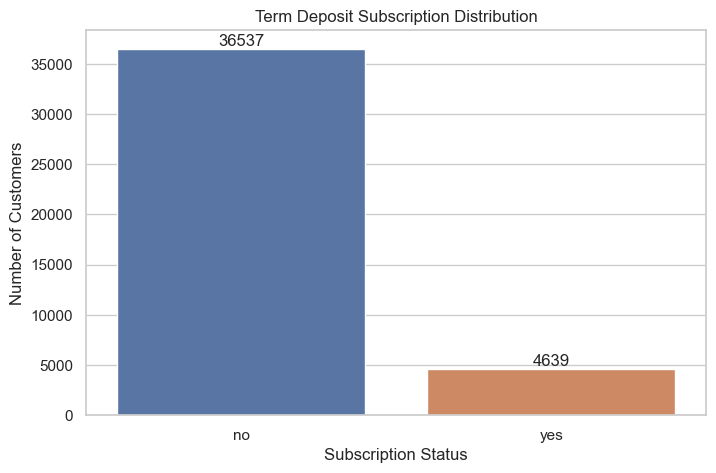

In [17]:
# Count customers in each target category
target_counts = df["y"].value_counts()

print("Target Variable Distribution:")
display(target_counts)

# Calculate percentages
target_percentage = (
    df["y"].value_counts(normalize=True) * 100
).round(2)

print("\nTarget Percentage:")
display(target_percentage)

# Visualization
plt.figure(figsize=(8, 5))

ax = sns.countplot(data=df, x="y", hue="y", legend=False)

plt.title("Term Deposit Subscription Distribution")
plt.xlabel("Subscription Status")
plt.ylabel("Number of Customers")

for container in ax.containers:
    ax.bar_label(container, fmt="%.0f")

plt.show()

Numerical Columns:
['age', 'duration', 'campaign', 'pdays', 'previous', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']


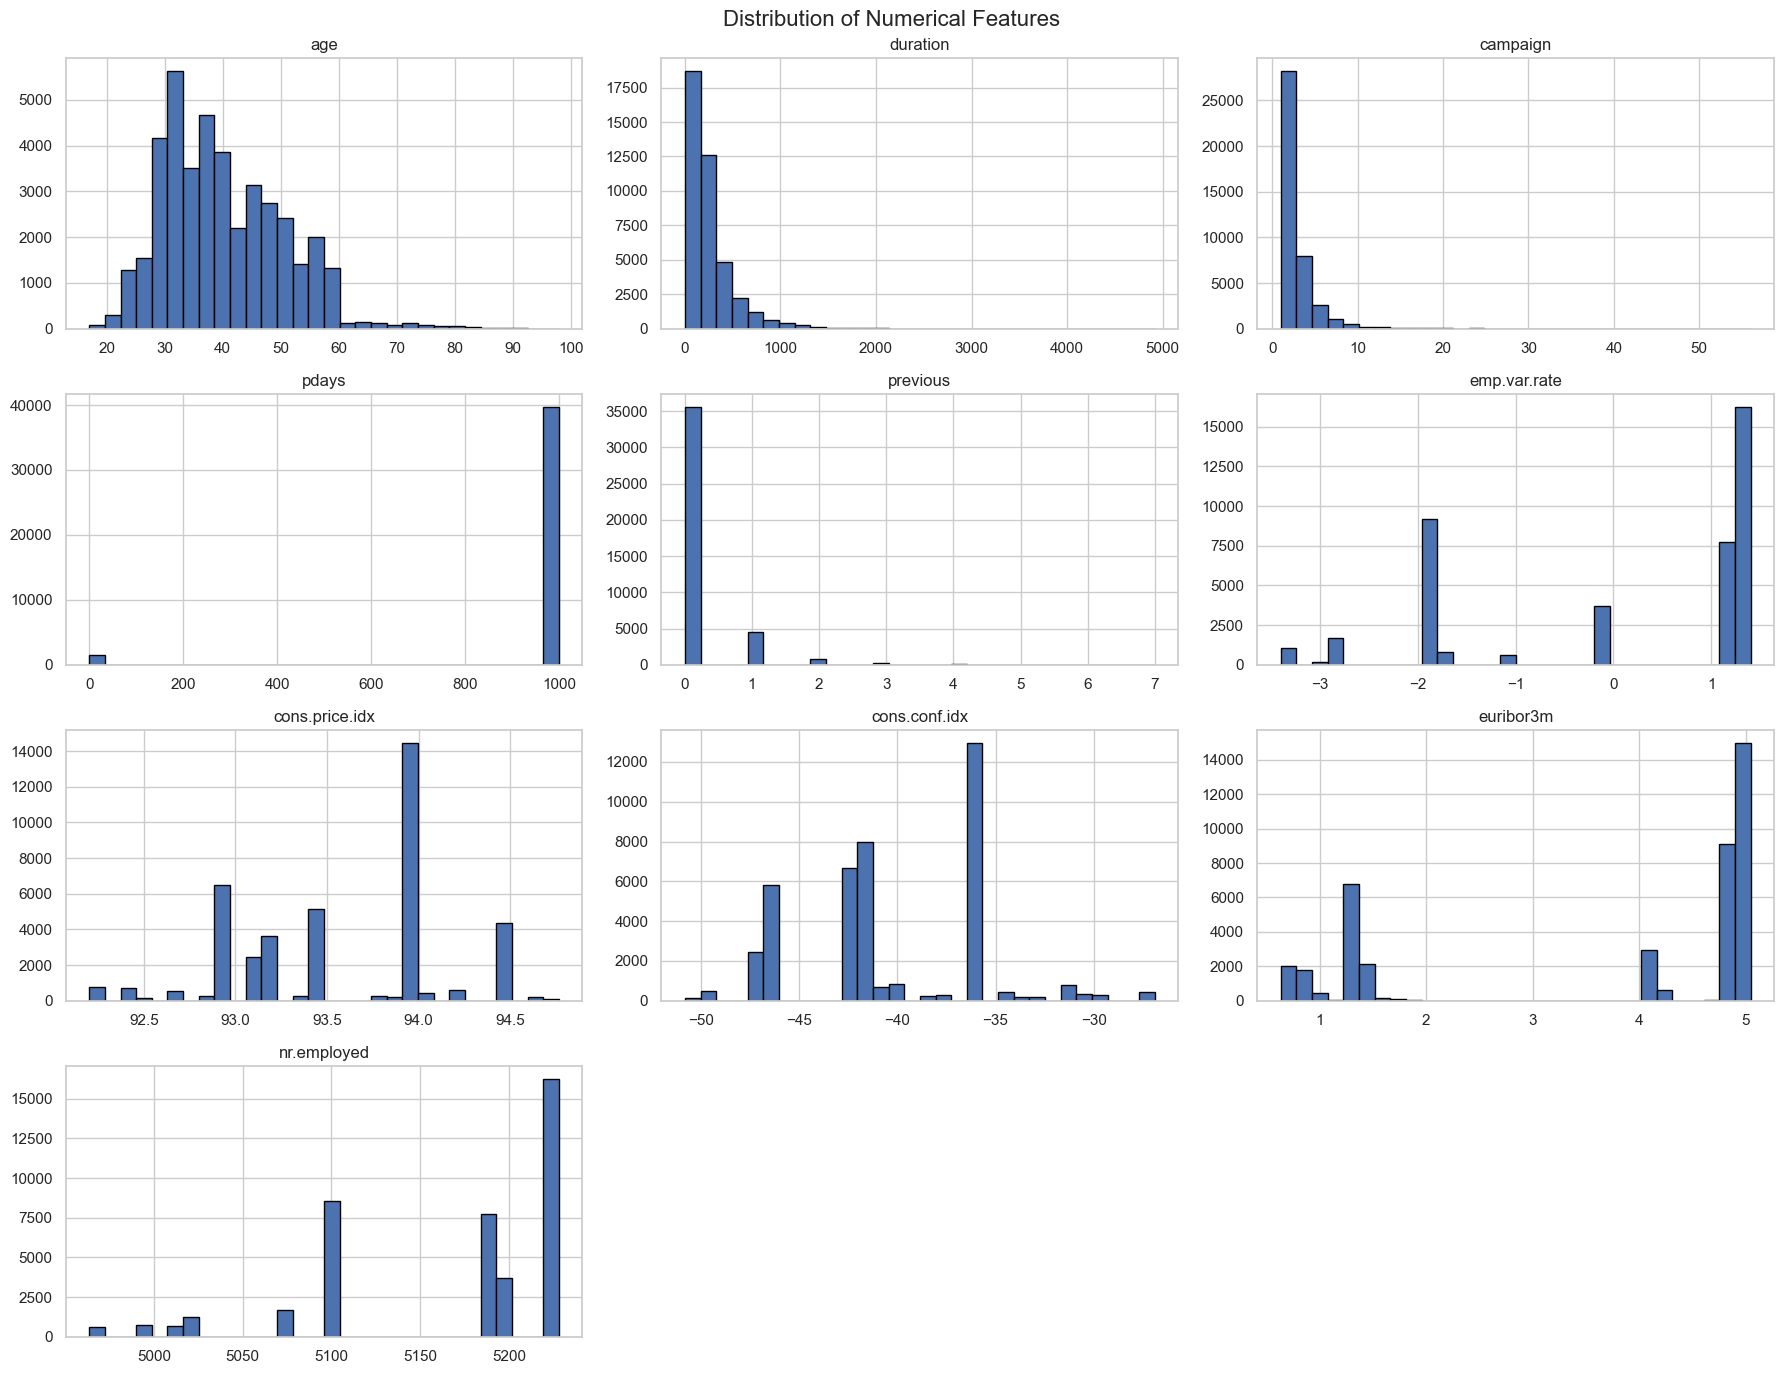

In [18]:
# Numerical columns distribution
numerical_columns = df.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

print("Numerical Columns:")
print(numerical_columns)

df[numerical_columns].hist(
    figsize=(18, 14),
    bins=30,
    edgecolor="black"
)

plt.suptitle("Distribution of Numerical Features", fontsize=16)
plt.tight_layout()
plt.show()

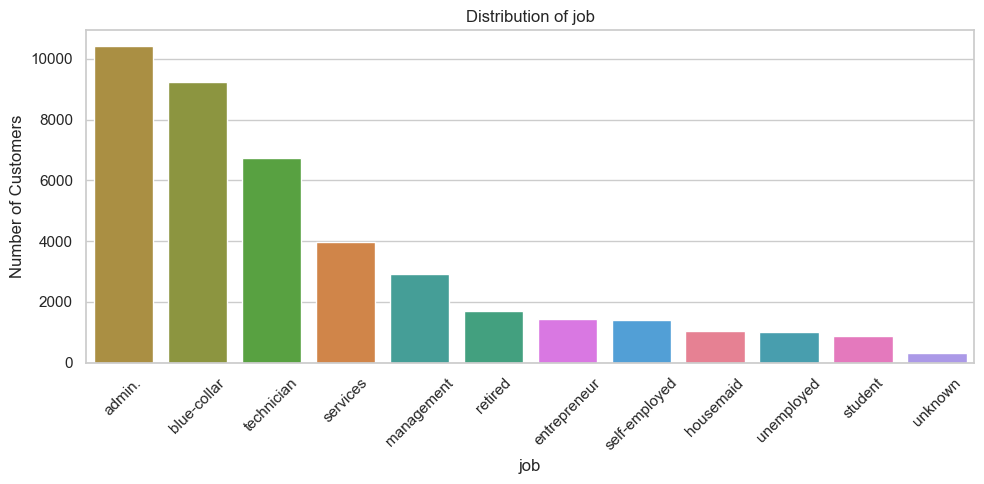

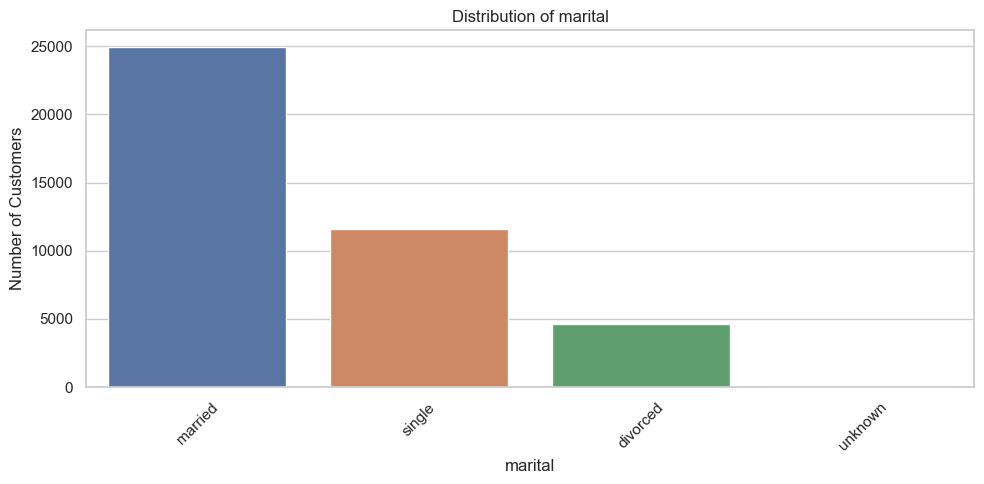

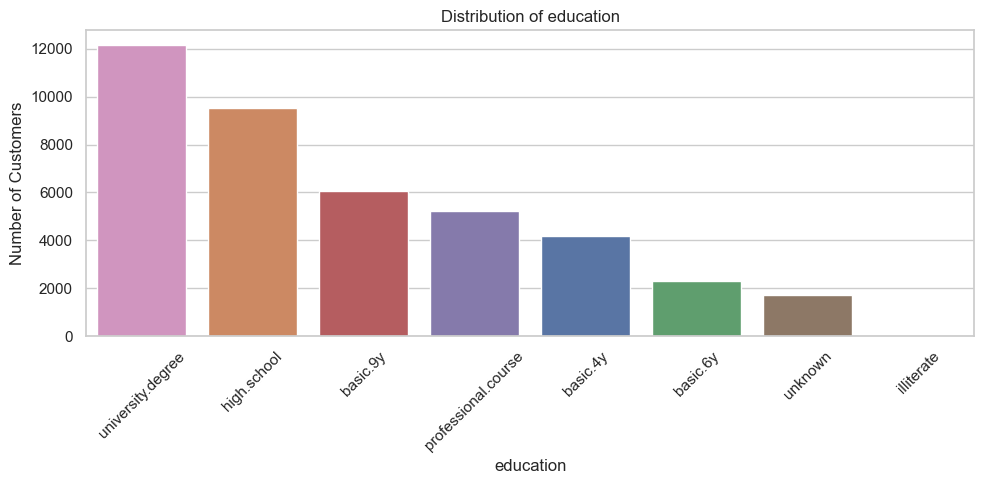

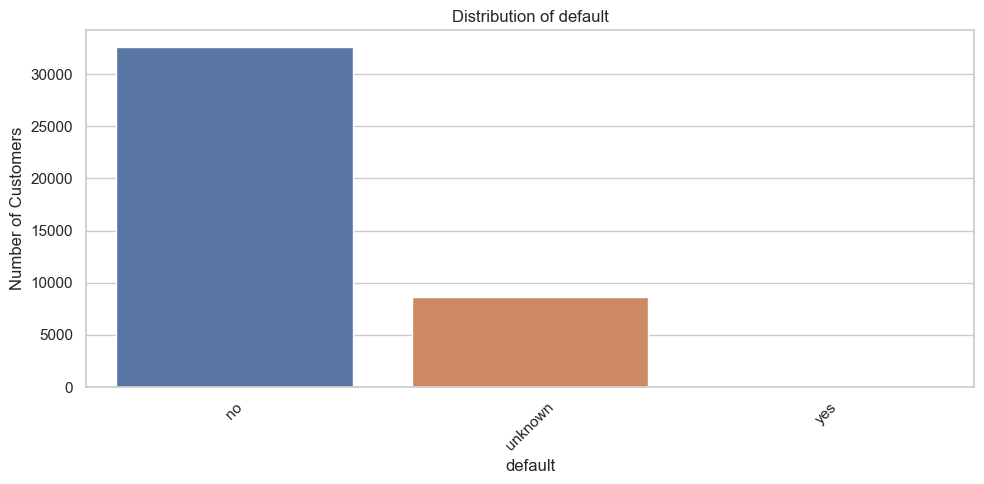

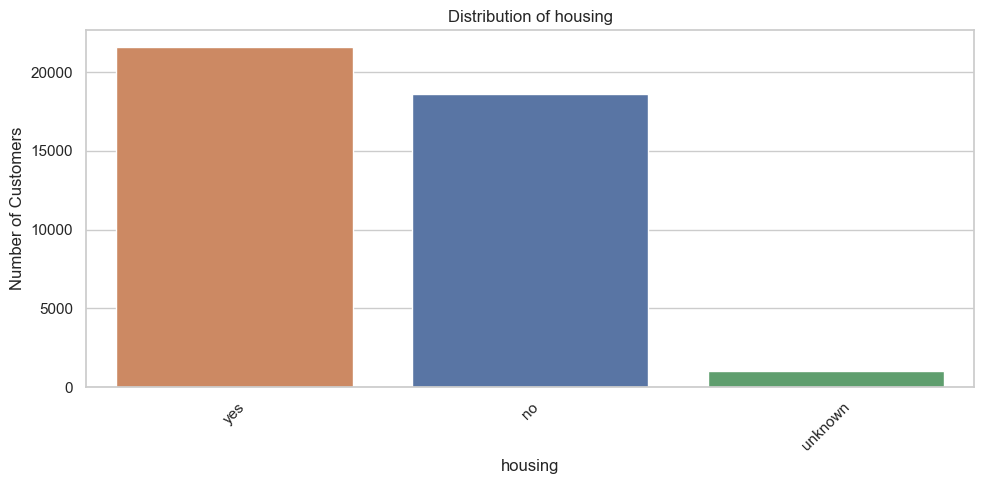

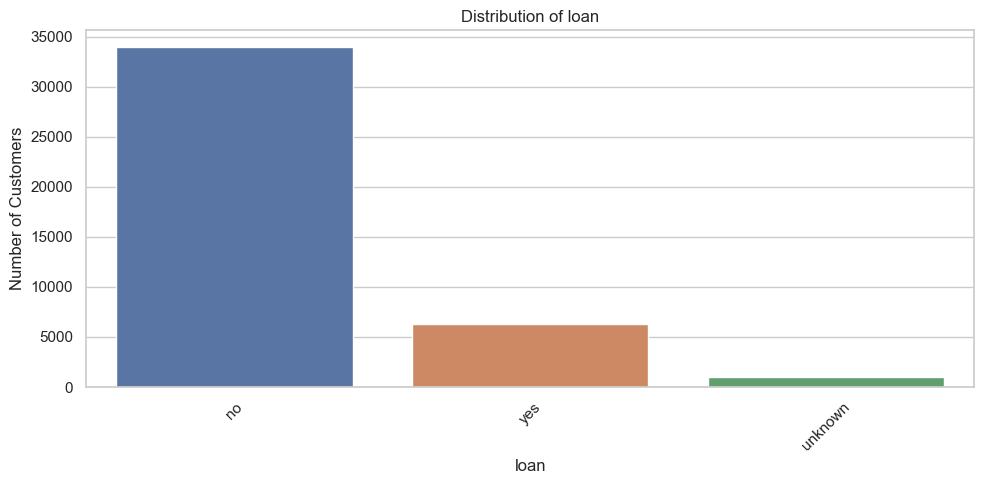

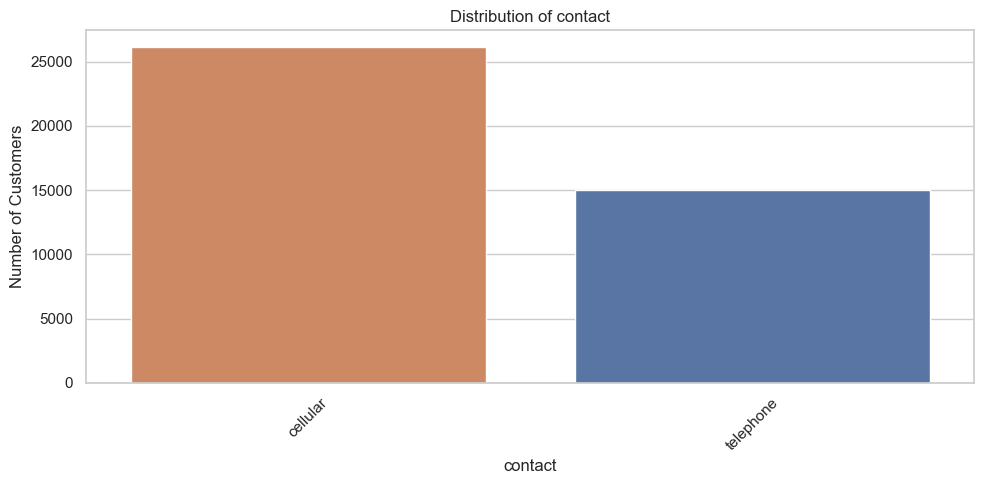

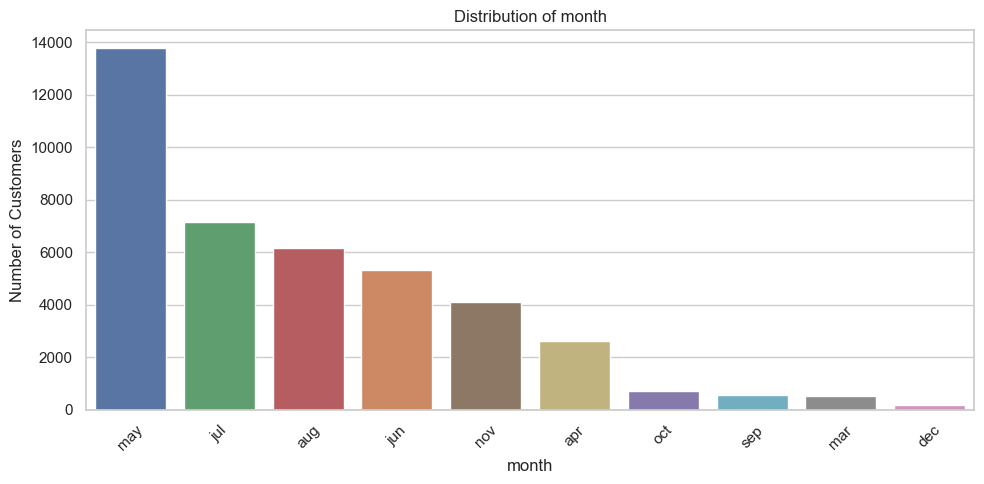

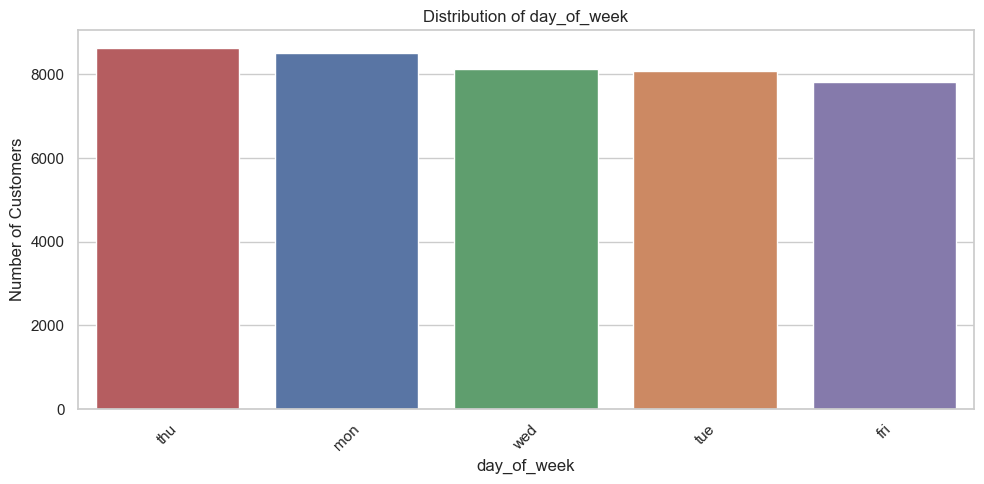

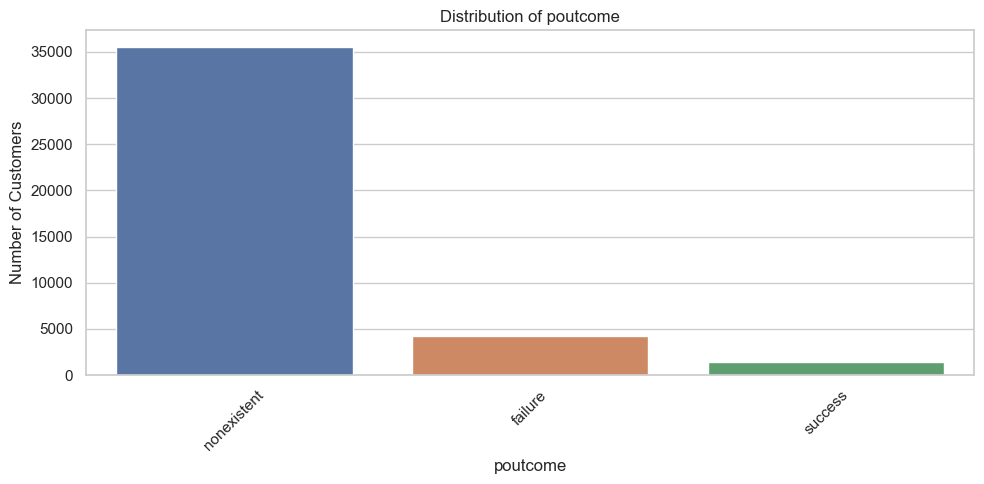

In [19]:
# Categorical distributions

categorical_columns = df.select_dtypes(
    include="object"
).columns.tolist()

categorical_columns.remove("y")

for column in categorical_columns:

    plt.figure(figsize=(10, 5))

    order = df[column].value_counts().index

    sns.countplot(
        data=df,
        x=column,
        hue=column,
        order=order,
        legend=False
    )

    plt.title(f"Distribution of {column}")
    plt.xlabel(column)
    plt.ylabel("Number of Customers")
    plt.xticks(rotation=45)

    plt.tight_layout()
    plt.show()

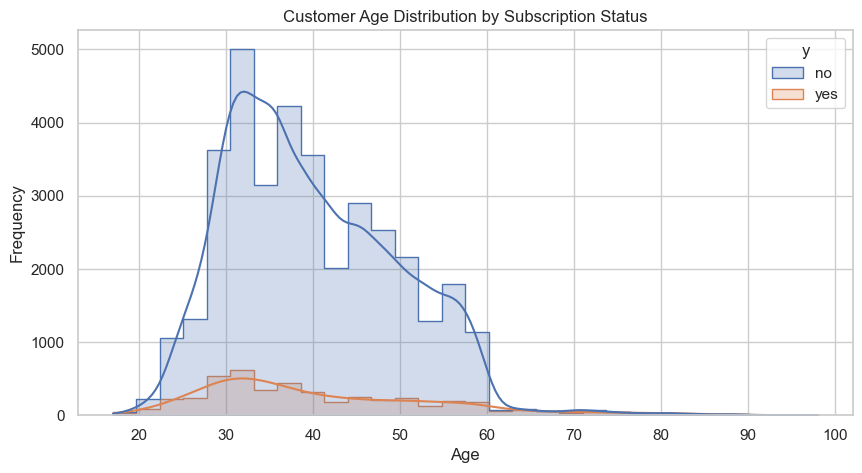

In [20]:
# Customer age analysis

plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="age",
    hue="y",
    bins=30,
    kde=True,
    element="step"
)

plt.title("Customer Age Distribution by Subscription Status")
plt.xlabel("Age")
plt.ylabel("Frequency")

plt.show()

y,no,yes
job,,
student,68.57,31.43
retired,74.74,25.26
unemployed,85.80,14.20
admin.,87.03,12.97
management,88.78,11.22
unknown,88.79,11.21
technician,89.17,10.83
self-employed,89.51,10.49
housemaid,90.00,10.00


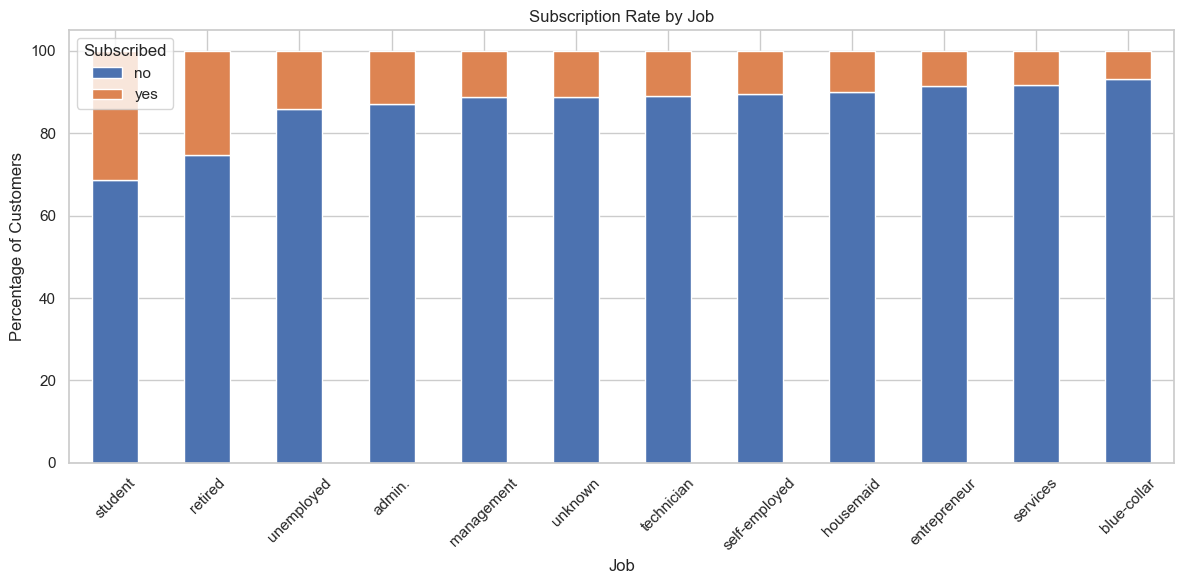

In [21]:
# Subscription analysis by customer job

job_subscription = pd.crosstab(
    df["job"],
    df["y"],
    normalize="index"
) * 100

job_subscription = job_subscription.sort_values(
    by="yes",
    ascending=False
)

display(job_subscription.round(2))

job_subscription.plot(
    kind="bar",
    stacked=True,
    figsize=(12, 6)
)

plt.title("Subscription Rate by Job")
plt.xlabel("Job")
plt.ylabel("Percentage of Customers")
plt.xticks(rotation=45)
plt.legend(title="Subscribed")

plt.tight_layout()
plt.show()

y,no,yes
education,,
basic.4y,89.75,10.25
basic.6y,91.79,8.21
basic.9y,92.18,7.82
high.school,89.16,10.84
illiterate,77.78,22.22
professional.course,88.65,11.35
university.degree,86.28,13.72
unknown,85.49,14.51


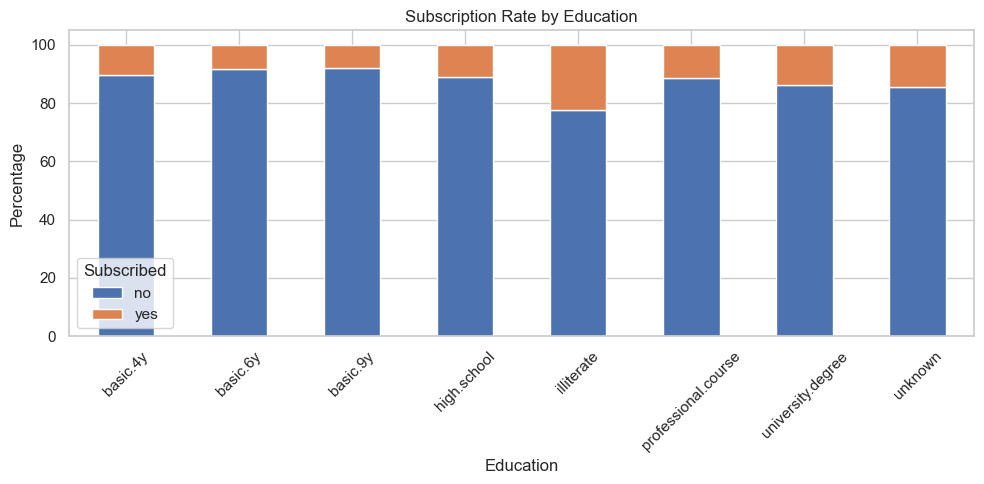

In [22]:
# Subscription analysis by education
education_subscription = pd.crosstab(
    df["education"],
    df["y"],
    normalize="index"
) * 100

display(education_subscription.round(2))

education_subscription.plot(
    kind="bar",
    stacked=True,
    figsize=(10, 5)
)

plt.title("Subscription Rate by Education")
plt.xlabel("Education")
plt.ylabel("Percentage")
plt.xticks(rotation=45)
plt.legend(title="Subscribed")

plt.tight_layout()
plt.show()

y,no,yes
marital,,
divorced,89.68,10.32
married,89.84,10.16
single,85.99,14.01
unknown,85.00,15.00


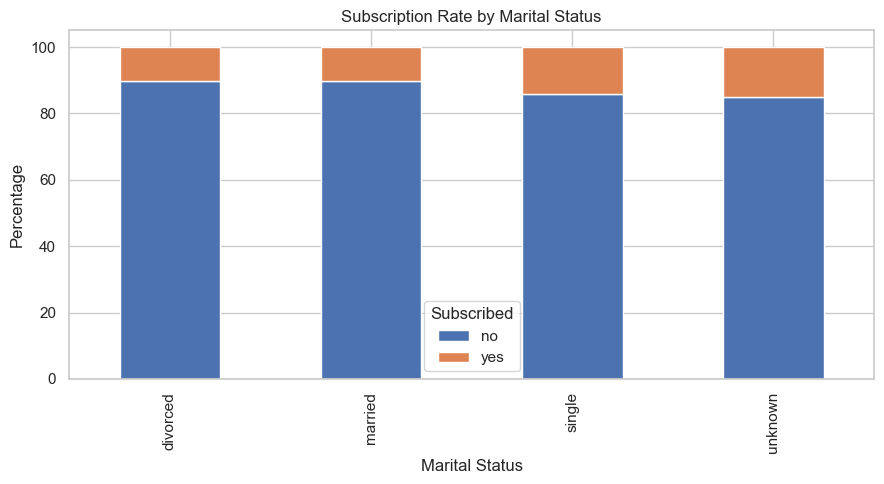

In [23]:
# Subscription analysis by marital status

marital_subscription = pd.crosstab(
    df["marital"],
    df["y"],
    normalize="index"
) * 100

display(marital_subscription.round(2))

marital_subscription.plot(
    kind="bar",
    stacked=True,
    figsize=(9, 5)
)

plt.title("Subscription Rate by Marital Status")
plt.xlabel("Marital Status")
plt.ylabel("Percentage")
plt.legend(title="Subscribed")

plt.tight_layout()
plt.show()

y,no,yes
contact,,
cellular,85.26,14.74
telephone,94.77,5.23


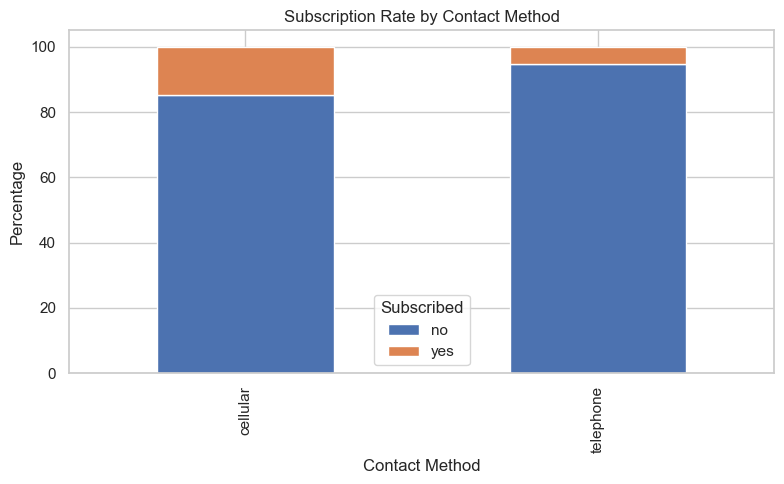

In [24]:
#Subscription analysis by contact method

contact_subscription = pd.crosstab(
    df["contact"],
    df["y"],
    normalize="index"
) * 100

display(contact_subscription.round(2))

contact_subscription.plot(
    kind="bar",
    stacked=True,
    figsize=(8, 5)
)

plt.title("Subscription Rate by Contact Method")
plt.xlabel("Contact Method")
plt.ylabel("Percentage")
plt.legend(title="Subscribed")

plt.tight_layout()
plt.show()

y,no,yes
month,,
mar,49.45,50.55
apr,79.51,20.49
may,93.56,6.44
jun,89.49,10.51
jul,90.96,9.04
aug,89.39,10.61
sep,55.09,44.91
oct,56.07,43.93
nov,89.85,10.15


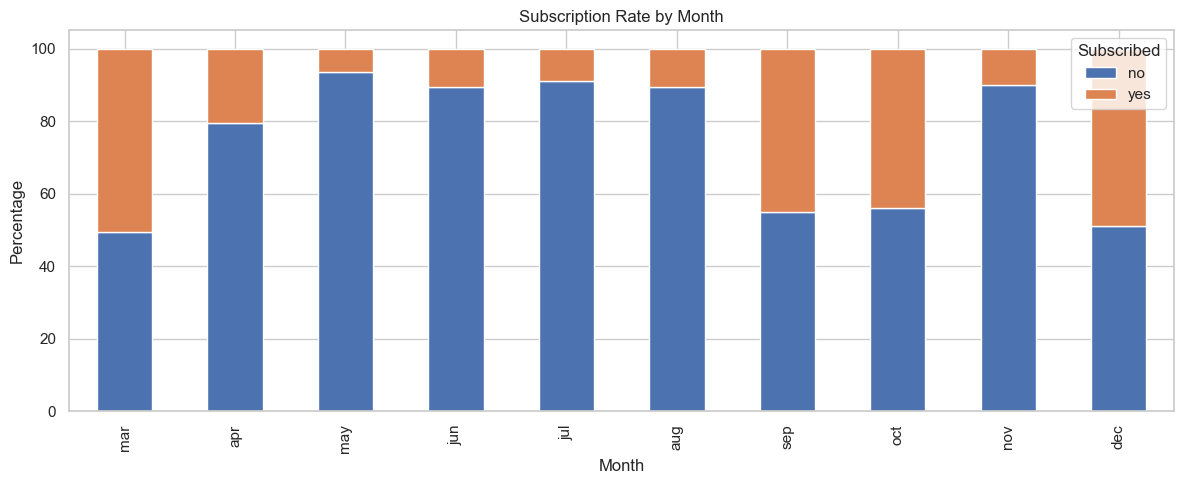

In [25]:
#Subscription analysis by month

month_order = [
    "jan", "feb", "mar", "apr", "may", "jun",
    "jul", "aug", "sep", "oct", "nov", "dec"
]

month_subscription = pd.crosstab(
    df["month"],
    df["y"],
    normalize="index"
) * 100

month_subscription = month_subscription.reindex(month_order).dropna()

display(month_subscription.round(2))

month_subscription.plot(
    kind="bar",
    stacked=True,
    figsize=(12, 5)
)

plt.title("Subscription Rate by Month")
plt.xlabel("Month")
plt.ylabel("Percentage")
plt.legend(title="Subscribed")

plt.tight_layout()
plt.show()

## Step 5: Advanced Exploratory Data Analysis

This section investigates correlations, customer campaign history,
previous campaign outcomes, and economic indicators.

The objective is to identify important patterns that may influence
term deposit subscription.

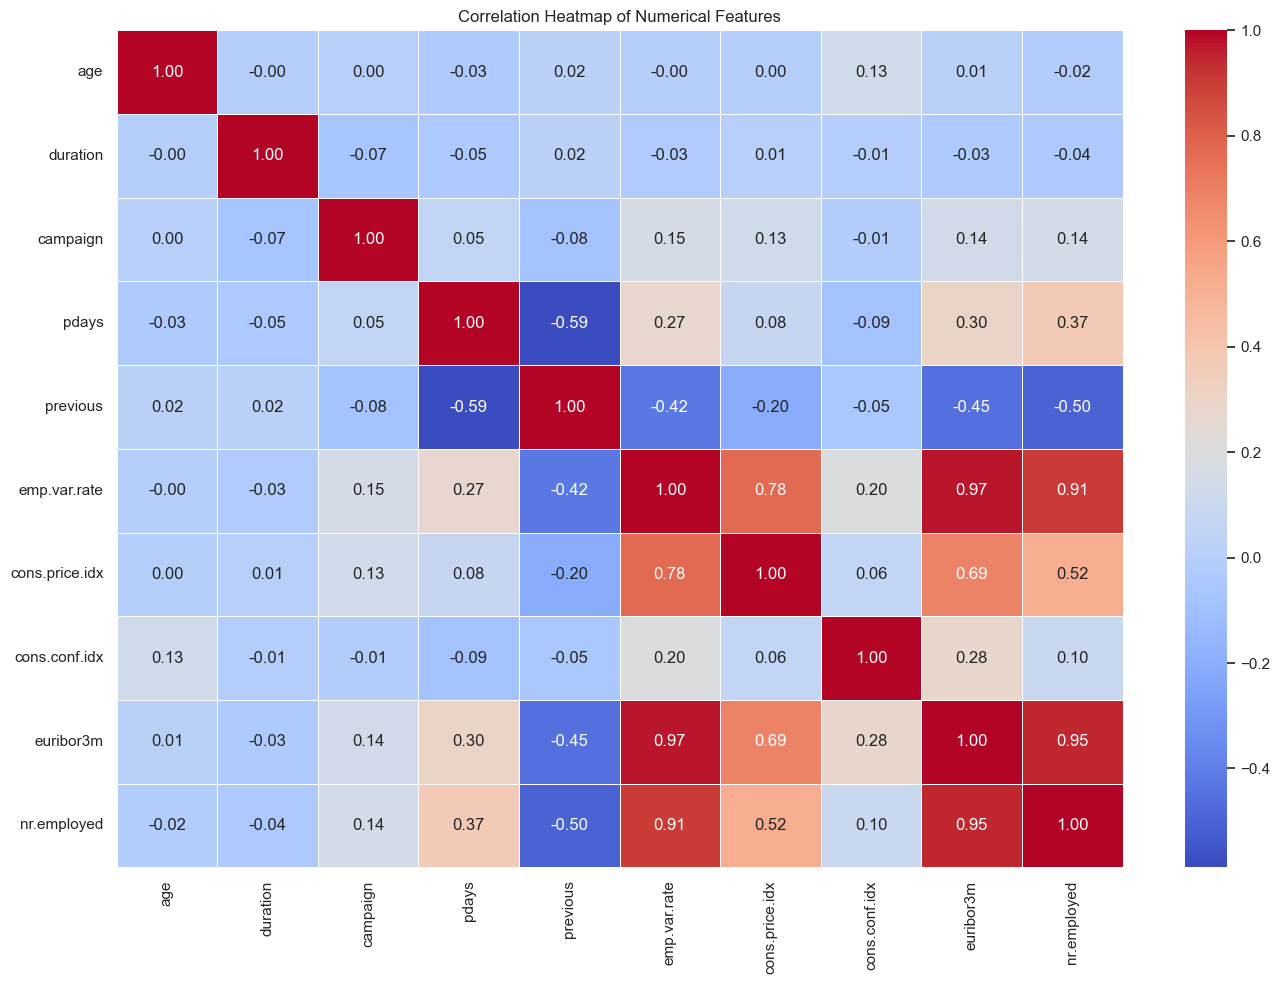

In [26]:
# Select numerical columns
numerical_df = df.select_dtypes(include=["int64", "float64"])

# Calculate correlation
correlation_matrix = numerical_df.corr()

plt.figure(figsize=(14, 10))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap of Numerical Features")
plt.tight_layout()
plt.show()

campaign
1     13.04
2     11.46
3     10.75
4      9.40
5      7.50
6      7.66
7      6.04
8      4.25
9      6.01
10     5.33
11     6.78
12     2.40
13     4.35
14     1.45
15     3.92
Name: y, dtype: float64

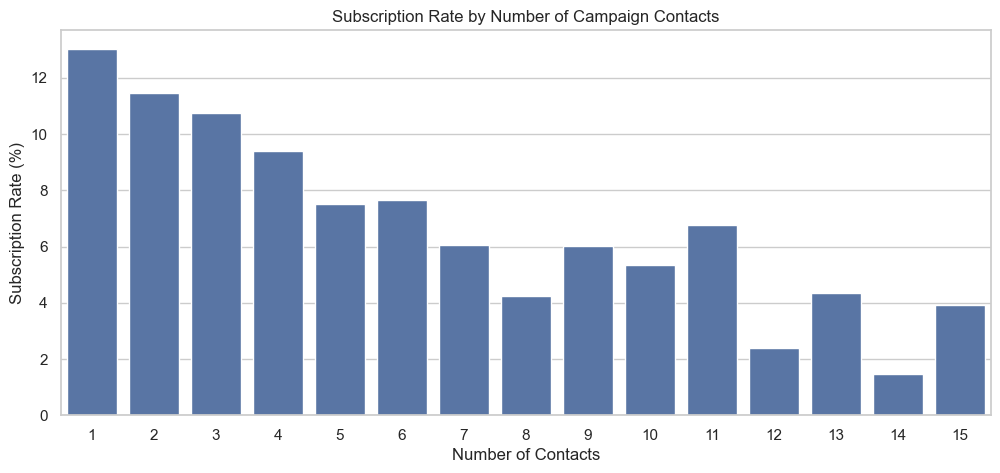

In [28]:
# Subscription rate by campaign contacts

campaign_subscription = df.groupby("campaign")["y"].apply(
    lambda x: (x == "yes").mean() * 100
)

campaign_subscription = campaign_subscription.head(15)

display(campaign_subscription.round(2))

plt.figure(figsize=(12, 5))

sns.barplot(
    x=campaign_subscription.index,
    y=campaign_subscription.values
)

plt.title("Subscription Rate by Number of Campaign Contacts")
plt.xlabel("Number of Contacts")
plt.ylabel("Subscription Rate (%)")

plt.show()

y,no,yes
poutcome,,
failure,85.77,14.23
nonexistent,91.17,8.83
success,34.89,65.11


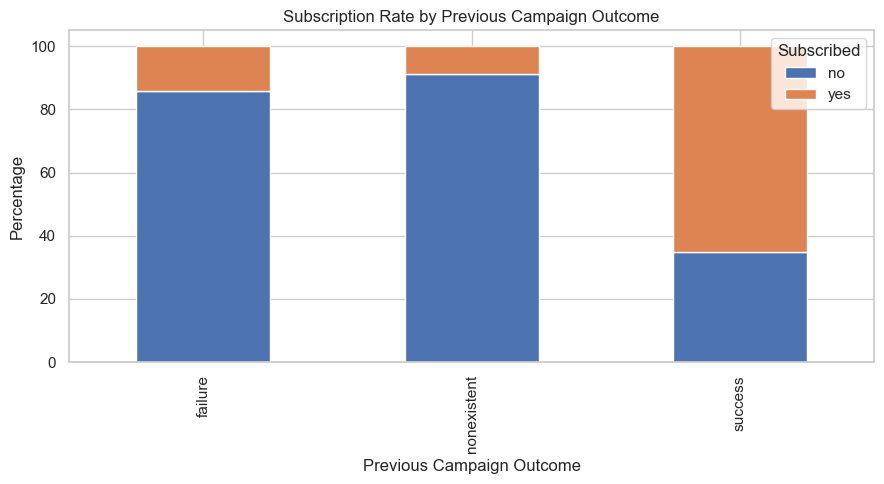

In [29]:
# Previous campaign outcome

poutcome_subscription = pd.crosstab(
    df["poutcome"],
    df["y"],
    normalize="index"
) * 100

display(poutcome_subscription.round(2))

poutcome_subscription.plot(
    kind="bar",
    stacked=True,
    figsize=(9, 5)
)

plt.title("Subscription Rate by Previous Campaign Outcome")
plt.xlabel("Previous Campaign Outcome")
plt.ylabel("Percentage")
plt.legend(title="Subscribed")

plt.tight_layout()
plt.show()

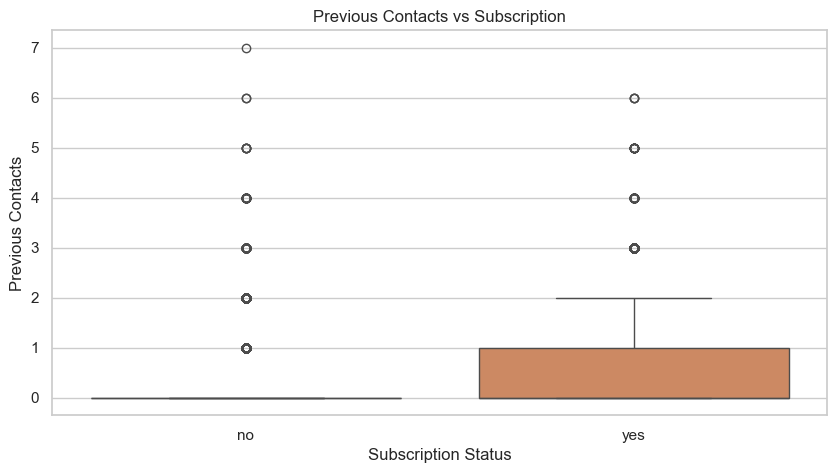

In [30]:
# Previous contact analysis
plt.figure(figsize=(10, 5))

sns.boxplot(
    data=df,
    x="y",
    y="previous",
    hue="y",
    legend=False
)

plt.title("Previous Contacts vs Subscription")
plt.xlabel("Subscription Status")
plt.ylabel("Previous Contacts")

plt.show()

In [31]:
# Economic indicators analysis

economic_columns = [
    "emp.var.rate",
    "cons.price.idx",
    "cons.conf.idx",
    "euribor3m",
    "nr.employed"
]

economic_summary = df.groupby("y")[economic_columns].mean().T

display(economic_summary.round(3))

y,no,yes
emp.var.rate,0.249,-1.233
cons.price.idx,93.604,93.355
cons.conf.idx,-40.593,-39.791
euribor3m,3.811,2.123
nr.employed,5176.166,5095.120


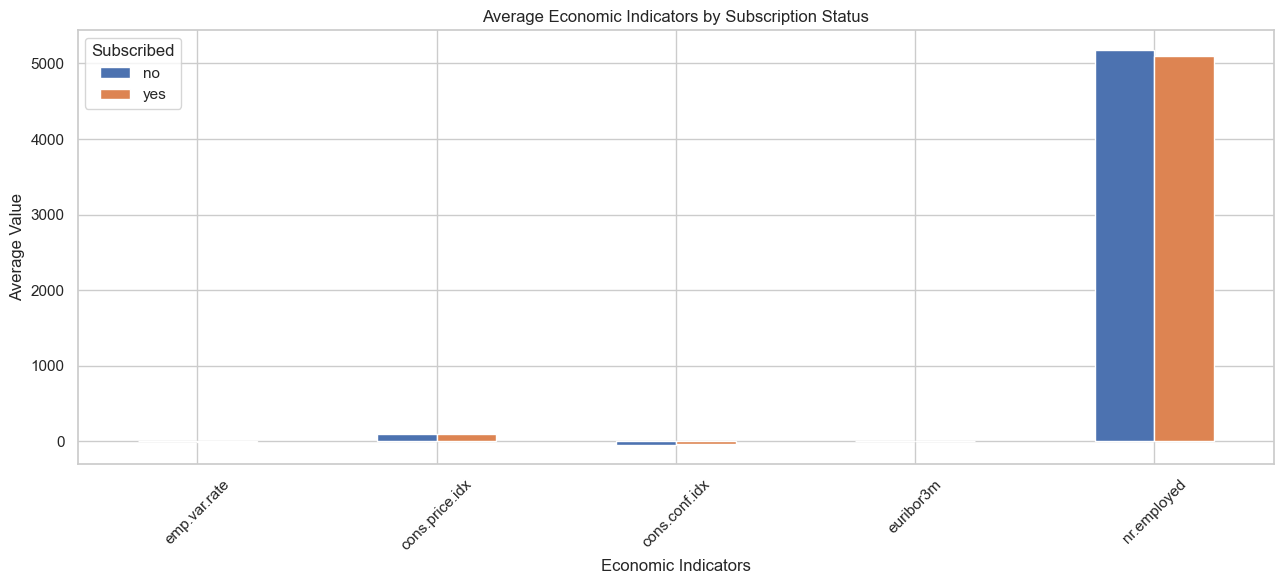

In [33]:
# Economic indicators visualization
economic_summary.plot(
    kind="bar",
    figsize=(13, 6)
)

plt.title("Average Economic Indicators by Subscription Status")
plt.xlabel("Economic Indicators")
plt.ylabel("Average Value")
plt.xticks(rotation=45)
plt.legend(title="Subscribed")

plt.tight_layout()
plt.show()

,count,mean,std,min,25%,50%,75%,max
y,,,,,,,,
no,36537.0,220.868079,207.116178,0.0,95.0,164.0,279.0,4918.0
yes,4639.0,553.256090,401.190736,37.0,253.5,449.0,741.5,4199.0


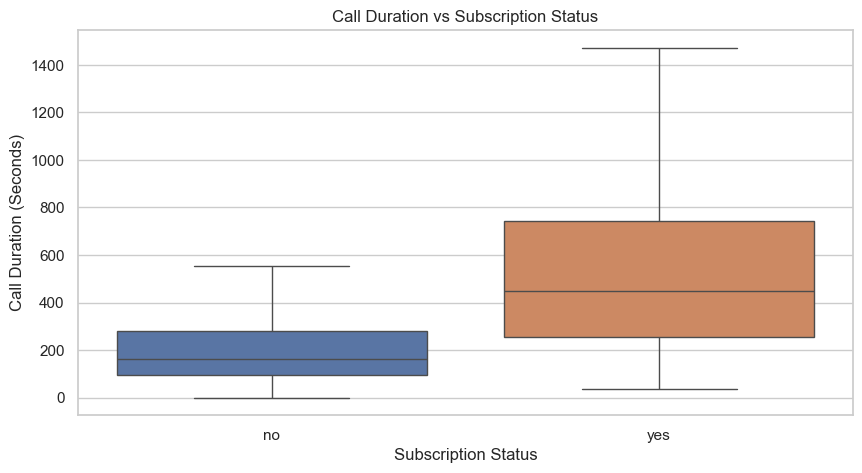

In [34]:
# Contact duration analysis — exploratory only
duration_summary = df.groupby("y")["duration"].describe()

display(duration_summary)

plt.figure(figsize=(10, 5))

sns.boxplot(
    data=df,
    x="y",
    y="duration",
    hue="y",
    legend=False,
    showfliers=False
)

plt.title("Call Duration vs Subscription Status")
plt.xlabel("Subscription Status")
plt.ylabel("Call Duration (Seconds)")

plt.show()

## Exploratory Data Analysis – Key Observations

1. The target variable contains two categories: yes and no.
2. Customer subscription distribution will be examined to identify
   class imbalance.
3. Customer demographics such as age, job, education and marital
   status may influence subscription behavior.
4. Contact method and campaign month may affect campaign performance.
5. Previous campaign outcomes may provide useful information about
   customer interest.
6. Campaign contact frequency will be investigated to identify
   possible diminishing returns.
7. Economic indicators may help explain differences in subscription
   behavior.
8. Call duration is strongly associated with subscription outcomes,
   but it will be excluded from the production prediction model
   because it is unavailable before a call.

### EDA Conclusion

The analysis helps identify customer characteristics and campaign
factors that can support predictive modeling and improve future
bank marketing strategies.

## Step 7: Feature Engineering and Data Preprocessing

This section prepares the dataset for machine learning.

The duration column will be excluded to prevent data leakage.
Unknown categorical values will be retained.

We will also create a feature indicating whether a customer
was contacted in a previous marketing campaign.

In [35]:
# Create a separate modeling dataset
model_df = df.copy()

# Remove duration to prevent data leakage
model_df = model_df.drop(columns=["duration"])

# Feature engineering:
# pdays = 999 means the customer was not previously contacted
model_df["previously_contacted"] = (
    model_df["pdays"] != 999
).astype(int)

# Replace the 999 sentinel with 0 for the new numeric feature
model_df["days_since_previous_contact"] = (
    model_df["pdays"].replace(999, 0)
)

# Remove original pdays column
model_df.drop(columns=["pdays"], inplace=True)

# Separate independent and dependent variables
X = model_df.drop(columns=["y"])
y = model_df["y"].map({"no": 0, "yes": 1})

print("Feature dataset shape:", X.shape)
print("Target dataset shape:", y.shape)

print("\nTarget classes:")
print(y.value_counts())

print("\nFeatures:")
print(X.columns.tolist())

print("\nMissing values in X:", X.isnull().sum().sum())
print("Missing values in y:", y.isnull().sum())


Feature dataset shape: (41176, 20)
Target dataset shape: (41176,)

Target classes:
y
0    36537
1     4639
Name: count, dtype: int64

Features:
['age', 'job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'campaign', 'previous', 'poutcome', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed', 'previously_contacted', 'days_since_previous_contact']

Missing values in X: 0
Missing values in y: 0


In [36]:
# Identify numerical features
numerical_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

# Identify categorical features
categorical_features = X.select_dtypes(
    include=["object"]
).columns.tolist()

print("Numerical features:")
print(numerical_features)

print("\nCategorical features:")
print(categorical_features)

print("\nNumber of numerical features:", len(numerical_features))
print("Number of categorical features:", len(categorical_features))

Numerical features:
['age', 'campaign', 'previous', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed', 'previously_contacted', 'days_since_previous_contact']

Categorical features:
['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome']

Number of numerical features: 10
Number of categorical features: 10


In [37]:
# Split the dataset into training and testing sets
from sklearn.model_selection import train_test_split

# Split dataset into 80% training and 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training feature shape:", X_train.shape)
print("Testing feature shape:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True).round(3))

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True).round(3))

Training feature shape: (32940, 20)
Testing feature shape: (8236, 20)

Training target distribution:
y
0    0.887
1    0.113
Name: proportion, dtype: float64

Testing target distribution:
y
0    0.887
1    0.113
Name: proportion, dtype: float64


In [38]:
# Build preprocessing pipeline

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline

# Numerical preprocessing
numeric_transformer = Pipeline(
    steps=[
        ("scaler", StandardScaler())
    ]
)

# Categorical preprocessing
categorical_transformer = Pipeline(
    steps=[
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ]
)

# Combine numerical and categorical preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numerical_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [39]:
# Fit preprocessing only on training data
X_train_processed = preprocessor.fit_transform(X_train)

# Transform testing data without fitting again
X_test_processed = preprocessor.transform(X_test)

print("Training data after preprocessing:",
      X_train_processed.shape)

print("Testing data after preprocessing:",
      X_test_processed.shape)

print("\nPreprocessing completed successfully!")

Training data after preprocessing: (32940, 63)
Testing data after preprocessing: (8236, 63)

Preprocessing completed successfully!


## Step 8: Machine Learning Model Training

In this section, multiple classification algorithms are trained
to predict whether a bank customer will subscribe to a term deposit.

Model performance will be evaluated using multiple classification
metrics, with special attention to identifying positive customers.

In [42]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    GradientBoostingClassifier,
    ExtraTreesClassifier,
    HistGradientBoostingClassifier
)

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    classification_report,
    confusion_matrix
)

from sklearn.pipeline import Pipeline

print("Machine learning libraries imported successfully!")

Machine learning libraries imported successfully!


In [43]:
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ),

    "Decision Tree": DecisionTreeClassifier(
        max_depth=10,
        min_samples_split=20,
        class_weight="balanced",
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        max_depth=15,
        min_samples_split=10,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ),

    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=100,
        learning_rate=0.05,
        max_depth=3,
        random_state=42
    ),

    "Extra Trees": ExtraTreesClassifier(
        n_estimators=200,
        max_depth=15,
        min_samples_split=10,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ),

    "HistGradientBoosting": HistGradientBoostingClassifier(
        max_iter=100,
        learning_rate=0.05,
        max_leaf_nodes=15,
        random_state=42
    )
}

print("Total models:", len(models))

Total models: 6


In [45]:

# Train and evaluate all models

results = []
trained_models = {}

for name, model in models.items():

    print(f"\nTraining {name}...")

    # Create complete pipeline
    pipeline = Pipeline(
        steps=[
            ("preprocessor", preprocessor),
            ("classifier", model)
        ]
    )

    # Train model
    pipeline.fit(X_train, y_train)

    # Predictions
    y_pred = pipeline.predict(X_test)

    # Probability predictions
    y_prob = pipeline.predict_proba(X_test)[:, 1]

    # Calculate evaluation metrics
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, zero_division=0)
    recall = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)
    roc_auc = roc_auc_score(y_test, y_prob)
    pr_auc = average_precision_score(y_test, y_prob)

    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1,
        "ROC-AUC": roc_auc,
        "PR-AUC": pr_auc
    })

    trained_models[name] = pipeline

    print(f"{name} completed.")
    print(f"Accuracy: {accuracy:.4f}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall: {recall:.4f}")
    print(f"F1 Score: {f1:.4f}")
    print(f"ROC-AUC: {roc_auc:.4f}")
    print(f"PR-AUC: {pr_auc:.4f}")

print("\nAll models trained successfully!")


Training Logistic Regression...
Logistic Regression completed.
Accuracy: 0.8304
Precision: 0.3593
Recall: 0.6455
F1 Score: 0.4617
ROC-AUC: 0.8001
PR-AUC: 0.4460

Training Decision Tree...
Decision Tree completed.
Accuracy: 0.8434
Precision: 0.3797
Recall: 0.6153
F1 Score: 0.4696
ROC-AUC: 0.7769
PR-AUC: 0.4486

Training Random Forest...
Random Forest completed.
Accuracy: 0.8743
Precision: 0.4561
Recall: 0.5991
F1 Score: 0.5179
ROC-AUC: 0.8106
PR-AUC: 0.4766

Training Gradient Boosting...
Gradient Boosting completed.
Accuracy: 0.8981
Precision: 0.6508
Recall: 0.2069
F1 Score: 0.3140
ROC-AUC: 0.8038
PR-AUC: 0.4757

Training Extra Trees...
Extra Trees completed.
Accuracy: 0.8602
Precision: 0.4197
Recall: 0.6282
F1 Score: 0.5032
ROC-AUC: 0.8061
PR-AUC: 0.4717

Training HistGradientBoosting...
HistGradientBoosting completed.
Accuracy: 0.9008
Precision: 0.6657
Recall: 0.2403
F1 Score: 0.3531
ROC-AUC: 0.8146
PR-AUC: 0.4947

All models trained successfully!


In [46]:
# Create model comparison report

comparison_df = pd.DataFrame(results)

comparison_df = comparison_df.sort_values(
    by="PR-AUC",
    ascending=False
).reset_index(drop=True)

display(
    comparison_df.style.format({
        "Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1 Score": "{:.4f}",
        "ROC-AUC": "{:.4f}",
        "PR-AUC": "{:.4f}"
    })
)

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC,PR-AUC
0,HistGradientBoosting,0.9008,0.6657,0.2403,0.3531,0.8146,0.4947
1,Random Forest,0.8743,0.4561,0.5991,0.5179,0.8106,0.4766
2,Gradient Boosting,0.8981,0.6508,0.2069,0.3140,0.8038,0.4757
3,Extra Trees,0.8602,0.4197,0.6282,0.5032,0.8061,0.4717
4,Decision Tree,0.8434,0.3797,0.6153,0.4696,0.7769,0.4486
5,Logistic Regression,0.8304,0.3593,0.6455,0.4617,0.8001,0.4460


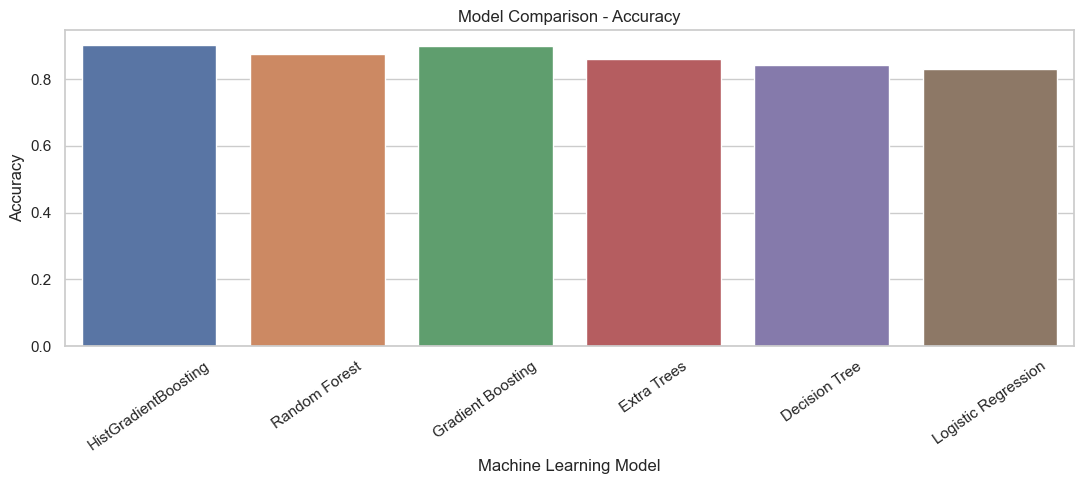

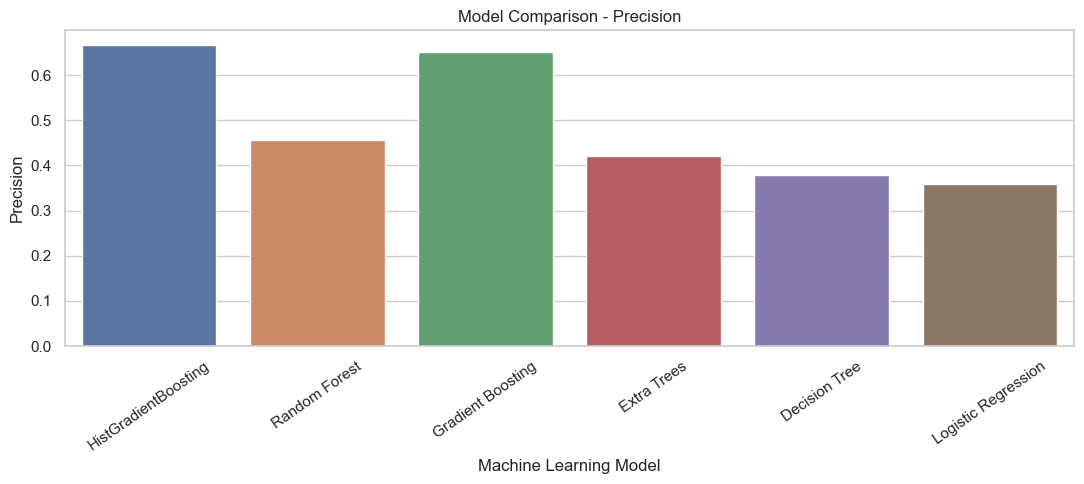

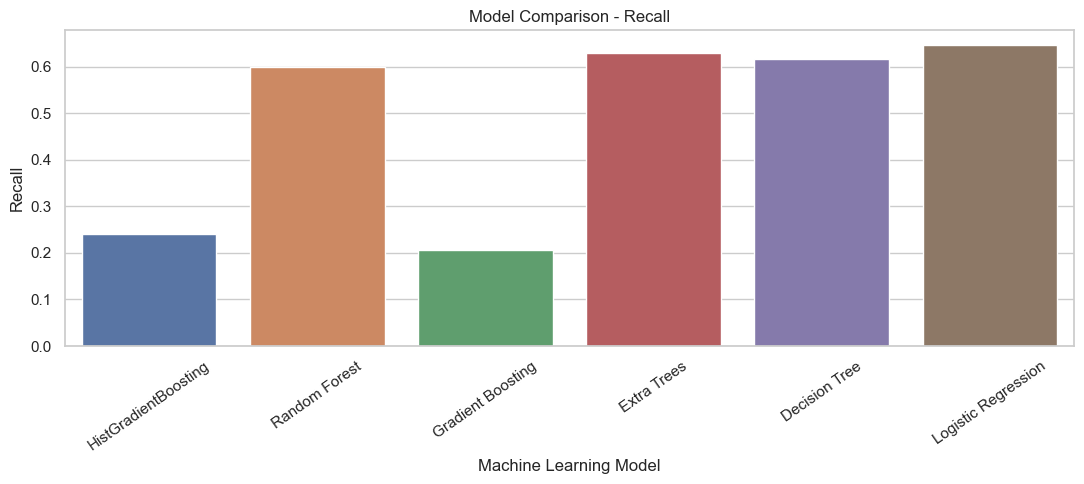

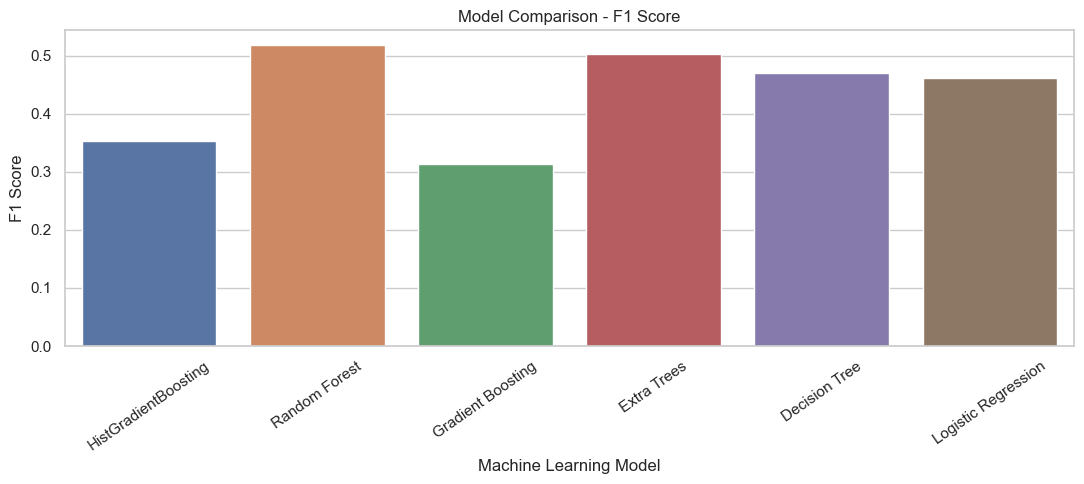

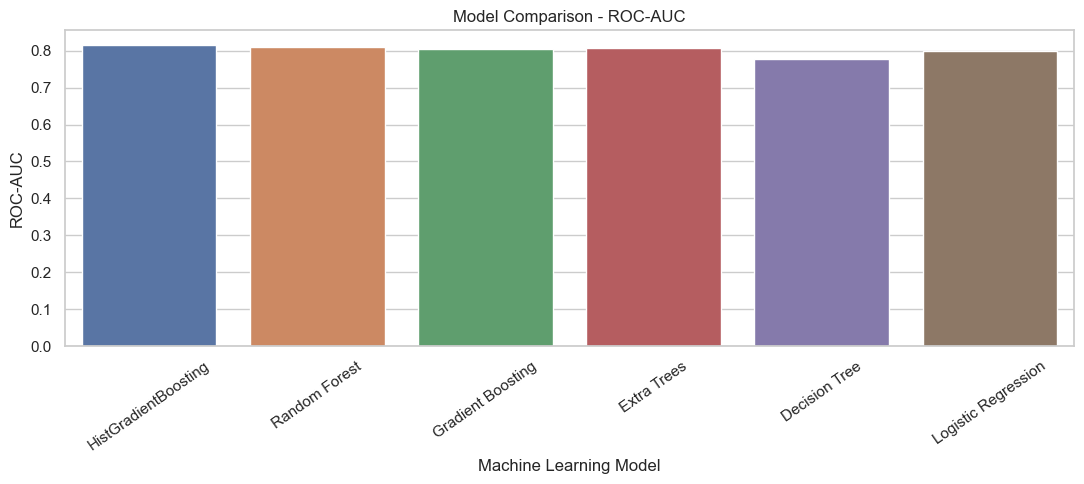

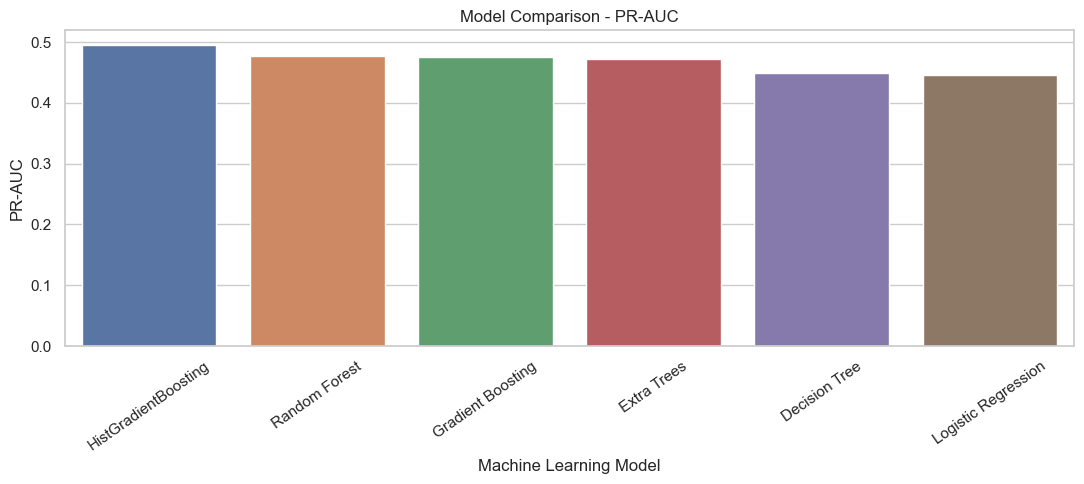

In [47]:
# Visualize model comparison
metrics_to_plot = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1 Score",
    "ROC-AUC",
    "PR-AUC"
]

for metric in metrics_to_plot:

    plt.figure(figsize=(11, 5))

    sns.barplot(
        data=comparison_df,
        x="Model",
        y=metric,
        hue="Model",
        legend=False
    )

    plt.title(f"Model Comparison - {metric}")
    plt.xlabel("Machine Learning Model")
    plt.ylabel(metric)
    plt.xticks(rotation=35)

    plt.tight_layout()
    plt.show()

In [48]:
# Classification report for each model
for name, pipeline in trained_models.items():

    print("\n" + "=" * 60)
    print("MODEL:", name)
    print("=" * 60)

    predictions = pipeline.predict(X_test)

    print(
        classification_report(
            y_test,
            predictions,
            target_names=["No Subscription", "Subscription"],
            zero_division=0
        )
    )


MODEL: Logistic Regression
                 precision    recall  f1-score   support

No Subscription       0.95      0.85      0.90      7308
   Subscription       0.36      0.65      0.46       928

       accuracy                           0.83      8236
      macro avg       0.65      0.75      0.68      8236
   weighted avg       0.88      0.83      0.85      8236


MODEL: Decision Tree
                 precision    recall  f1-score   support

No Subscription       0.95      0.87      0.91      7308
   Subscription       0.38      0.62      0.47       928

       accuracy                           0.84      8236
      macro avg       0.66      0.74      0.69      8236
   weighted avg       0.88      0.84      0.86      8236


MODEL: Random Forest
                 precision    recall  f1-score   support

No Subscription       0.95      0.91      0.93      7308
   Subscription       0.46      0.60      0.52       928

       accuracy                           0.87      8236
      ma

## Step 9: Advanced Model Evaluation

This section evaluates the classification performance of each model
using confusion matrices, ROC curves, Precision-Recall curves,
and cross-validation.

The objective is to identify a reliable model for production.


Confusion Matrix: Logistic Regression
[[6240 1068]
 [ 329  599]]


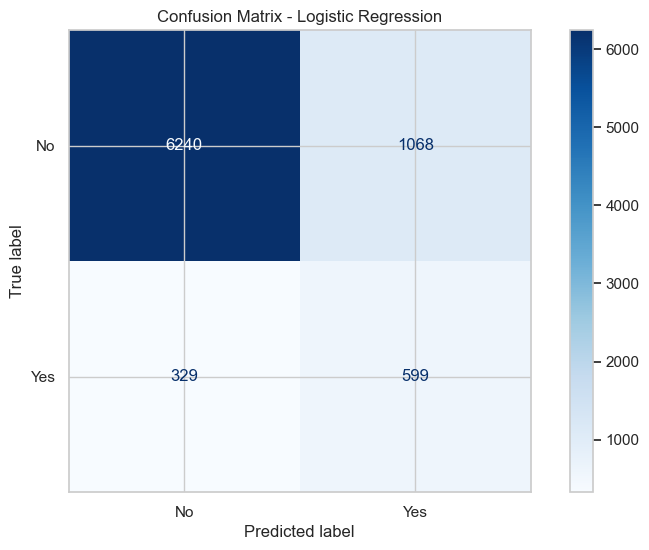


Confusion Matrix: Decision Tree
[[6375  933]
 [ 357  571]]


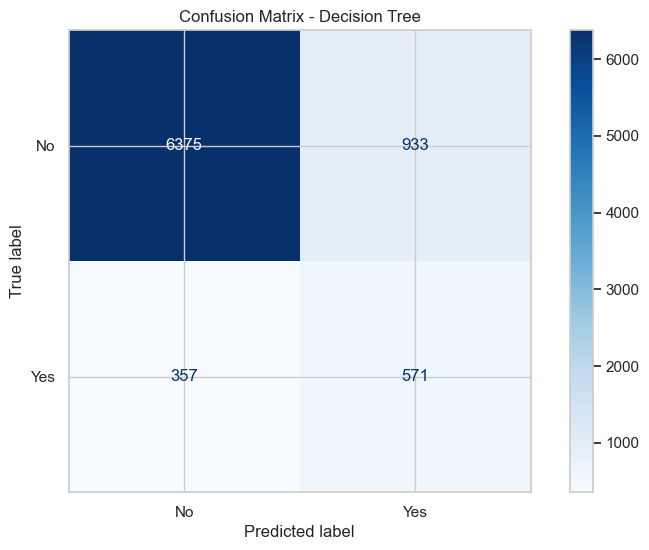


Confusion Matrix: Random Forest
[[6645  663]
 [ 372  556]]


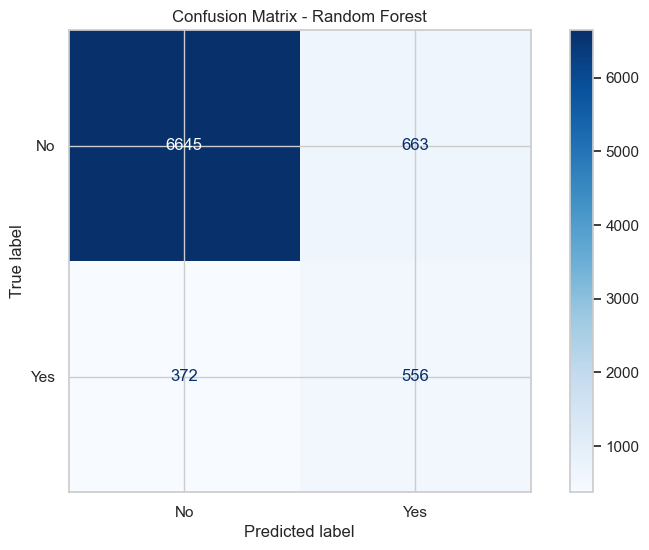


Confusion Matrix: Gradient Boosting
[[7205  103]
 [ 736  192]]


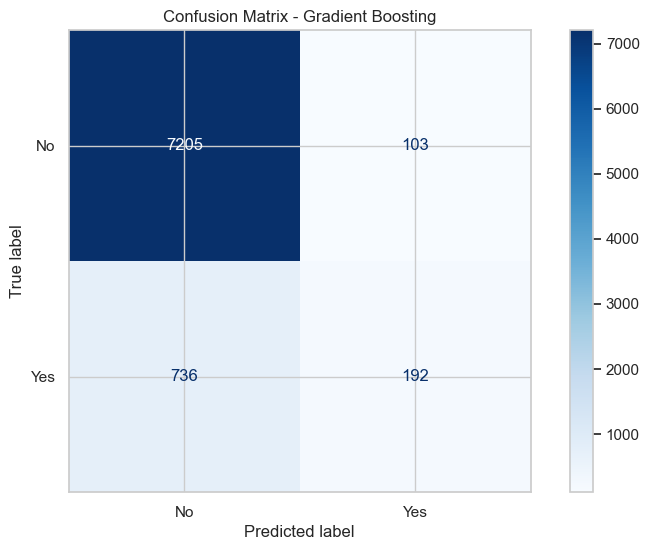


Confusion Matrix: Extra Trees
[[6502  806]
 [ 345  583]]


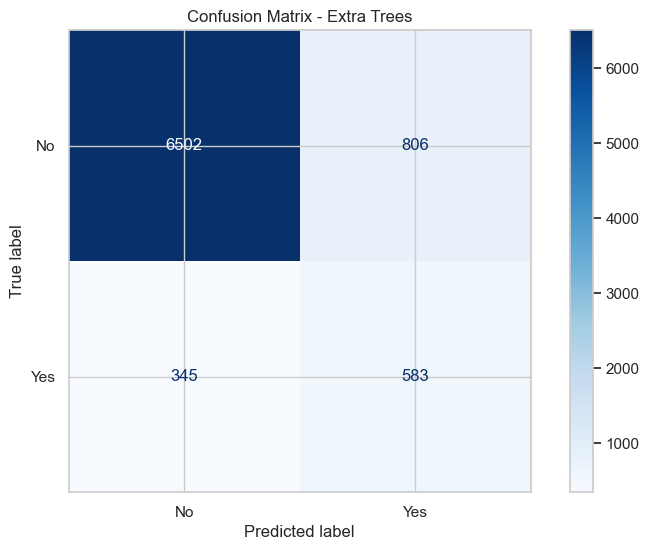


Confusion Matrix: HistGradientBoosting
[[7196  112]
 [ 705  223]]


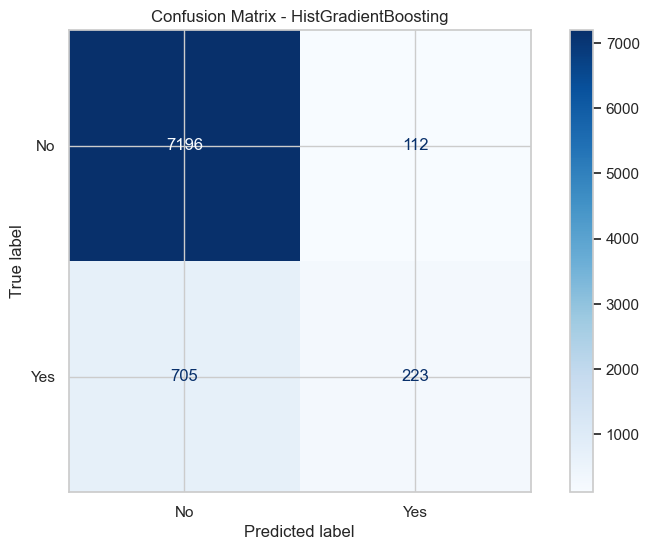

In [49]:
from sklearn.metrics import ConfusionMatrixDisplay

for name, pipeline in trained_models.items():

    predictions = pipeline.predict(X_test)

    cm = confusion_matrix(y_test, predictions)

    print(f"\nConfusion Matrix: {name}")
    print(cm)

    ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["No", "Yes"]
    ).plot(cmap="Blues", values_format="d")

    plt.title(f"Confusion Matrix - {name}")
    plt.show()

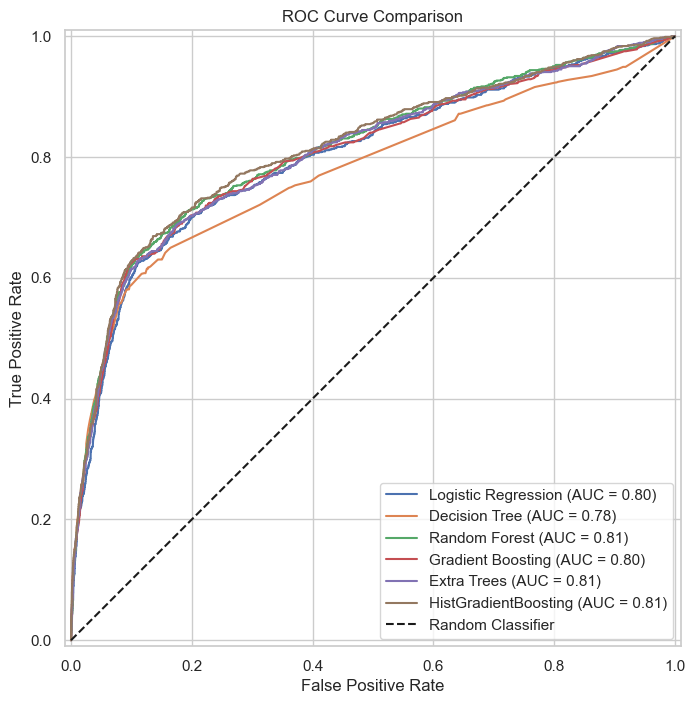

In [50]:
# Compare ROC curves
from sklearn.metrics import RocCurveDisplay

plt.figure(figsize=(10, 8))

for name, pipeline in trained_models.items():

    RocCurveDisplay.from_estimator(
        pipeline,
        X_test,
        y_test,
        name=name,
        ax=plt.gca()
    )

plt.plot([0, 1], [0, 1], "k--", label="Random Classifier")

plt.title("ROC Curve Comparison")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.show()

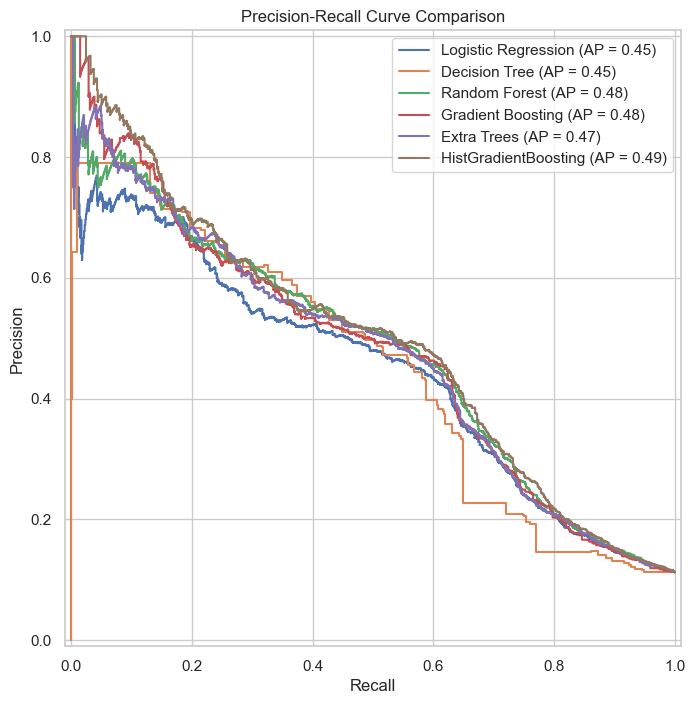

In [51]:
from sklearn.metrics import PrecisionRecallDisplay

plt.figure(figsize=(10, 8))

for name, pipeline in trained_models.items():

    PrecisionRecallDisplay.from_estimator(
        pipeline,
        X_test,
        y_test,
        name=name,
        ax=plt.gca()
    )

plt.title("Precision-Recall Curve Comparison")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.legend()
plt.show()

In [52]:
from sklearn.model_selection import StratifiedKFold, cross_validate

scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc",
    "average_precision": "average_precision"
}

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_results = []

for name, model in models.items():

    print(f"Cross-validating: {name}")

    pipeline = Pipeline(
        steps=[
            ("preprocessor", preprocessor),
            ("classifier", model)
        ]
    )

    scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1
    )

    cv_results.append({
        "Model": name,
        "CV Accuracy": scores["test_accuracy"].mean(),
        "CV Precision": scores["test_precision"].mean(),
        "CV Recall": scores["test_recall"].mean(),
        "CV F1": scores["test_f1"].mean(),
        "CV ROC-AUC": scores["test_roc_auc"].mean(),
        "CV PR-AUC": scores["test_average_precision"].mean()
    })

cv_comparison_df = pd.DataFrame(cv_results)

cv_comparison_df = cv_comparison_df.sort_values(
    by="CV PR-AUC",
    ascending=False
).reset_index(drop=True)

display(cv_comparison_df.round(4))

Cross-validating: Logistic Regression
Cross-validating: Decision Tree
Cross-validating: Random Forest
Cross-validating: Gradient Boosting
Cross-validating: Extra Trees
Cross-validating: HistGradientBoosting


,Model,CV Accuracy,CV Precision,CV Recall,CV F1,CV ROC-AUC,CV PR-AUC
0,HistGradientBoosting,0.9010,0.6657,0.2441,0.3571,0.8016,0.4674
1,Gradient Boosting,0.9012,0.6831,0.2309,0.3451,0.7937,0.4619
2,Random Forest,0.8711,0.4433,0.5602,0.4948,0.7959,0.4542
3,Extra Trees,0.8539,0.3992,0.5866,0.4750,0.7919,0.4488
4,Logistic Regression,0.8287,0.3526,0.6222,0.4501,0.7906,0.4458
5,Decision Tree,0.8383,0.3656,0.5899,0.4511,0.7600,0.4155


In [53]:
print("Test-set model comparison:")
display(comparison_df.round(4))

print("\nCross-validation model comparison:")
display(cv_comparison_df.round(4))

best_model_name = cv_comparison_df.iloc[0]["Model"]

print("\nBest candidate based on CV PR-AUC:")
print(best_model_name)

Test-set model comparison:


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC,PR-AUC
0,HistGradientBoosting,0.9008,0.6657,0.2403,0.3531,0.8146,0.4947
1,Random Forest,0.8743,0.4561,0.5991,0.5179,0.8106,0.4766
2,Gradient Boosting,0.8981,0.6508,0.2069,0.3140,0.8038,0.4757
3,Extra Trees,0.8602,0.4197,0.6282,0.5032,0.8061,0.4717
4,Decision Tree,0.8434,0.3797,0.6153,0.4696,0.7769,0.4486
5,Logistic Regression,0.8304,0.3593,0.6455,0.4617,0.8001,0.4460



Cross-validation model comparison:


,Model,CV Accuracy,CV Precision,CV Recall,CV F1,CV ROC-AUC,CV PR-AUC
0,HistGradientBoosting,0.9010,0.6657,0.2441,0.3571,0.8016,0.4674
1,Gradient Boosting,0.9012,0.6831,0.2309,0.3451,0.7937,0.4619
2,Random Forest,0.8711,0.4433,0.5602,0.4948,0.7959,0.4542
3,Extra Trees,0.8539,0.3992,0.5866,0.4750,0.7919,0.4488
4,Logistic Regression,0.8287,0.3526,0.6222,0.4501,0.7906,0.4458
5,Decision Tree,0.8383,0.3656,0.5899,0.4511,0.7600,0.4155



Best candidate based on CV PR-AUC:
HistGradientBoosting


## Step 10: Hyperparameter Tuning

Hyperparameter tuning is performed to improve the predictive
performance of the selected candidate model.

The training dataset will be used for tuning, while the test
dataset will remain untouched for final evaluation.

In [54]:
# Identify best candidate from cross-validation
best_model_name = cv_comparison_df.iloc[0]["Model"]

print("Selected candidate:", best_model_name)

candidate_model = models[best_model_name]

print("\nCandidate model configuration:")
print(candidate_model)

Selected candidate: HistGradientBoosting

Candidate model configuration:
HistGradientBoostingClassifier(learning_rate=0.05, max_leaf_nodes=15,
                               random_state=42)


In [55]:
from sklearn.model_selection import RandomizedSearchCV

param_grids = {
    "Logistic Regression": {
        "classifier__C": [0.01, 0.1, 1, 10, 100],
        "classifier__solver": ["lbfgs"],
        "classifier__class_weight": ["balanced"]
    },

    "Decision Tree": {
        "classifier__max_depth": [5, 8, 10, 15, 20, None],
        "classifier__min_samples_split": [10, 20, 30, 50],
        "classifier__min_samples_leaf": [2, 5, 10, 20],
        "classifier__class_weight": ["balanced"]
    },

    "Random Forest": {
        "classifier__n_estimators": [100, 200, 300],
        "classifier__max_depth": [10, 15, 20, None],
        "classifier__min_samples_split": [5, 10, 20],
        "classifier__min_samples_leaf": [2, 5, 10],
        "classifier__max_features": ["sqrt", "log2"],
        "classifier__class_weight": ["balanced", "balanced_subsample"]
    },

    "Gradient Boosting": {
        "classifier__n_estimators": [100, 150, 200],
        "classifier__learning_rate": [0.01, 0.03, 0.05, 0.1],
        "classifier__max_depth": [2, 3, 4],
        "classifier__min_samples_leaf": [5, 10, 20]
    },

    "Extra Trees": {
        "classifier__n_estimators": [100, 200, 300],
        "classifier__max_depth": [10, 15, 20, None],
        "classifier__min_samples_split": [5, 10, 20],
        "classifier__min_samples_leaf": [2, 5, 10],
        "classifier__max_features": ["sqrt", "log2"],
        "classifier__class_weight": ["balanced", "balanced_subsample"]
    },

    "HistGradientBoosting": {
        "classifier__max_iter": [100, 150, 200],
        "classifier__learning_rate": [0.01, 0.03, 0.05, 0.1],
        "classifier__max_leaf_nodes": [10, 15, 20, 31],
        "classifier__l2_regularization": [0, 0.1, 1, 5]
    }
}

print("Available tuning configurations:")
print(list(param_grids.keys()))

Available tuning configurations:
['Logistic Regression', 'Decision Tree', 'Random Forest', 'Gradient Boosting', 'Extra Trees', 'HistGradientBoosting']


In [56]:
# Create candidate pipeline
candidate_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", candidate_model)
    ]
)

# Randomized search
random_search = RandomizedSearchCV(
    estimator=candidate_pipeline,
    param_distributions=param_grids[best_model_name],
    n_iter=15,
    scoring="average_precision",
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

# Fit using training data only
random_search.fit(X_train, y_train)

print("\nHyperparameter tuning completed!")

print("\nBest parameters:")
print(random_search.best_params_)

print("\nBest cross-validation PR-AUC:")
print(round(random_search.best_score_, 4))

Fitting 5 folds for each of 15 candidates, totalling 75 fits

Hyperparameter tuning completed!

Best parameters:
{'classifier__max_leaf_nodes': 15, 'classifier__max_iter': 150, 'classifier__learning_rate': 0.03, 'classifier__l2_regularization': 0.1}

Best cross-validation PR-AUC:
0.4678


In [57]:
original_candidate_score = cv_comparison_df.loc[
    cv_comparison_df["Model"] == best_model_name,
    "CV PR-AUC"
].iloc[0]

tuned_candidate_score = random_search.best_score_

print("Candidate Model:", best_model_name)

print("Original CV PR-AUC:",
      round(original_candidate_score, 4))

print("Tuned CV PR-AUC:",
      round(tuned_candidate_score, 4))

if tuned_candidate_score > original_candidate_score:
    print("\nHyperparameter tuning improved CV PR-AUC.")
else:
    print("\nHyperparameter tuning did not improve CV PR-AUC.")

Candidate Model: HistGradientBoosting
Original CV PR-AUC: 0.4674
Tuned CV PR-AUC: 0.4678

Hyperparameter tuning improved CV PR-AUC.


In [58]:
tuned_candidate = random_search.best_estimator_

print("Tuned candidate model prepared successfully.")
print(tuned_candidate)

Tuned candidate model prepared successfully.
Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('scaler',
                                                                   StandardScaler())]),
                                                  ['age', 'campaign',
                                                   'previous', 'emp.var.rate',
                                                   'cons.price.idx',
                                                   'cons.conf.idx', 'euribor3m',
                                                   'nr.employed',
                                                   'previously_contacted',
                                                   'days_since_previous_contact']),
                                                 ('cat',
                                                  Pipeline(steps=[('onehot',
                                          

## Step 11: Final Model Evaluation

The tuned candidate model is evaluated on the independent test dataset.

We will analyze its accuracy, precision, recall, F1-score,
ROC-AUC, PR-AUC and confusion matrix.

In [59]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Predictions
y_pred_tuned = tuned_candidate.predict(X_test)

# Prediction probabilities
y_prob_tuned = tuned_candidate.predict_proba(X_test)[:, 1]

# Calculate metrics
final_metrics = {
    "Accuracy": accuracy_score(y_test, y_pred_tuned),
    "Precision": precision_score(y_test, y_pred_tuned),
    "Recall": recall_score(y_test, y_pred_tuned),
    "F1 Score": f1_score(y_test, y_pred_tuned),
    "ROC-AUC": roc_auc_score(y_test, y_prob_tuned),
    "PR-AUC": average_precision_score(y_test, y_prob_tuned)
}

print("Final Tuned Model:", best_model_name)

for metric, value in final_metrics.items():
    print(f"{metric}: {value:.4f}")

Final Tuned Model: HistGradientBoosting
Accuracy: 0.9006
Precision: 0.6667
Recall: 0.2349
F1 Score: 0.3474
ROC-AUC: 0.8139
PR-AUC: 0.4933


Confusion Matrix:
[[7199  109]
 [ 710  218]]


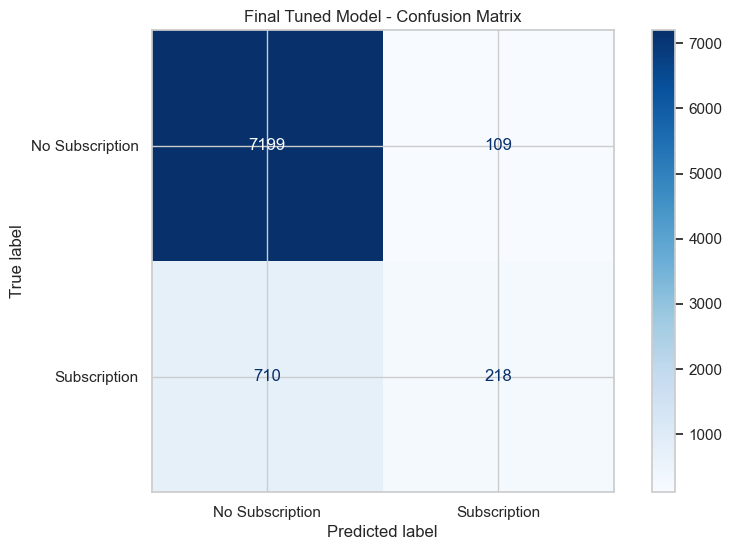

In [60]:
cm = confusion_matrix(y_test, y_pred_tuned)

print("Confusion Matrix:")
print(cm)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Subscription", "Subscription"]
).plot(cmap="Blues", values_format="d")

plt.title("Final Tuned Model - Confusion Matrix")
plt.show()

In [61]:
print(
    classification_report(
        y_test,
        y_pred_tuned,
        target_names=["No Subscription", "Subscription"],
        zero_division=0
    )
)

                 precision    recall  f1-score   support

No Subscription       0.91      0.99      0.95      7308
   Subscription       0.67      0.23      0.35       928

       accuracy                           0.90      8236
      macro avg       0.79      0.61      0.65      8236
   weighted avg       0.88      0.90      0.88      8236



In [62]:
from sklearn.metrics import precision_recall_curve

precision_values, recall_values, thresholds = precision_recall_curve(
    y_test,
    y_prob_tuned
)

threshold_results = []

for threshold in np.arange(0.10, 0.91, 0.05):

    predictions = (y_prob_tuned >= threshold).astype(int)

    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "F1 Score": f1_score(
            y_test, predictions, zero_division=0
        )
    })

threshold_df = pd.DataFrame(threshold_results)

display(threshold_df.round(4))

,Threshold,Precision,Recall,F1 Score
0,0.10,0.3510,0.6843,0.4640
1,0.15,0.4395,0.6304,0.5179
2,0.20,0.4731,0.6067,0.5316
3,0.25,0.4873,0.5787,0.5291
4,0.30,0.5093,0.5022,0.5057
5,0.35,0.5518,0.3901,0.4571
6,0.40,0.6122,0.3147,0.4157
7,0.45,0.6458,0.2672,0.3780
8,0.50,0.6667,0.2349,0.3474
9,0.55,0.7050,0.1983,0.3095


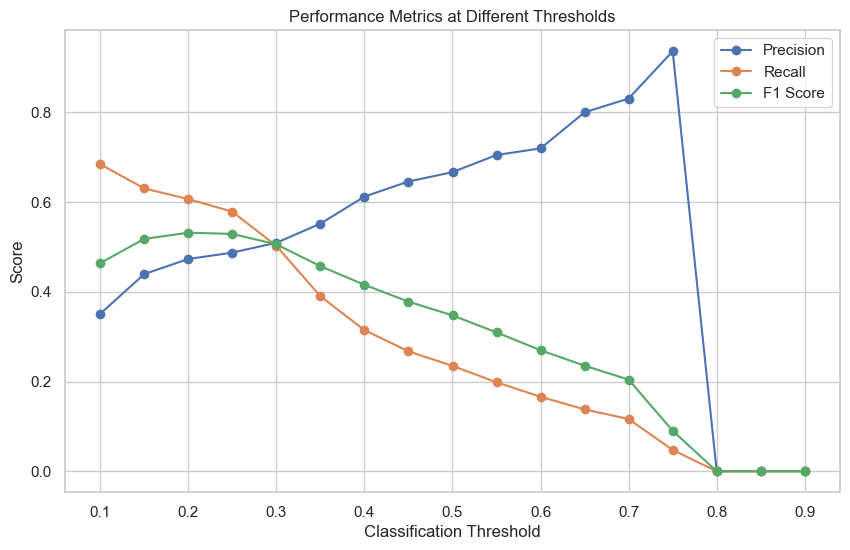

In [63]:
plt.figure(figsize=(10, 6))

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Precision"],
    marker="o",
    label="Precision"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Recall"],
    marker="o",
    label="Recall"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["F1 Score"],
    marker="o",
    label="F1 Score"
)

plt.title("Performance Metrics at Different Thresholds")
plt.xlabel("Classification Threshold")
plt.ylabel("Score")
plt.legend()
plt.grid(True)

plt.show()

In [64]:
final_comparison = comparison_df.copy()

tuned_row = pd.DataFrame([{
    "Model": best_model_name + " (Tuned)",
    "Accuracy": final_metrics["Accuracy"],
    "Precision": final_metrics["Precision"],
    "Recall": final_metrics["Recall"],
    "F1 Score": final_metrics["F1 Score"],
    "ROC-AUC": final_metrics["ROC-AUC"],
    "PR-AUC": final_metrics["PR-AUC"]
}])

final_comparison = pd.concat(
    [final_comparison, tuned_row],
    ignore_index=True
)

final_comparison = final_comparison.sort_values(
    by="PR-AUC",
    ascending=False
).reset_index(drop=True)

display(final_comparison.round(4))

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC,PR-AUC
0,HistGradientBoosting,0.9008,0.6657,0.2403,0.3531,0.8146,0.4947
1,HistGradientBoosting (Tuned),0.9006,0.6667,0.2349,0.3474,0.8139,0.4933
2,Random Forest,0.8743,0.4561,0.5991,0.5179,0.8106,0.4766
3,Gradient Boosting,0.8981,0.6508,0.2069,0.3140,0.8038,0.4757
4,Extra Trees,0.8602,0.4197,0.6282,0.5032,0.8061,0.4717
5,Decision Tree,0.8434,0.3797,0.6153,0.4696,0.7769,0.4486
6,Logistic Regression,0.8304,0.3593,0.6455,0.4617,0.8001,0.4460


## Step 12: Feature Importance and Model Interpretation

This section identifies the most influential features used by
the selected machine learning model.

The results will help the bank understand which factors influence
term deposit subscription predictions.

In [66]:

from sklearn.inspection import permutation_importance
import pandas as pd
import matplotlib.pyplot as plt

# Calculate permutation feature importance
perm_result = permutation_importance(
    tuned_candidate,
    X_test,
    y_test,
    n_repeats=5,
    random_state=42,
    scoring="average_precision",
    n_jobs=-1
)

# Create feature importance DataFrame
feature_importance_df = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance": perm_result.importances_mean,
    "Std": perm_result.importances_std
})

# Sort by importance
feature_importance_df = feature_importance_df.sort_values(
    by="Importance",
    ascending=False
).reset_index(drop=True)

# Display top 15 features
display(feature_importance_df.head(15))


,Feature,Importance,Std
0,nr.employed,0.186038,0.011221
1,euribor3m,0.056420,0.005041
2,contact,0.022873,0.003237
3,cons.price.idx,0.020131,0.001631
4,month,0.019100,0.003486
5,cons.conf.idx,0.014480,0.002237
6,campaign,0.012973,0.001179
7,day_of_week,0.012279,0.002269
8,days_since_previous_contact,0.008147,0.001833
9,poutcome,0.007450,0.003026


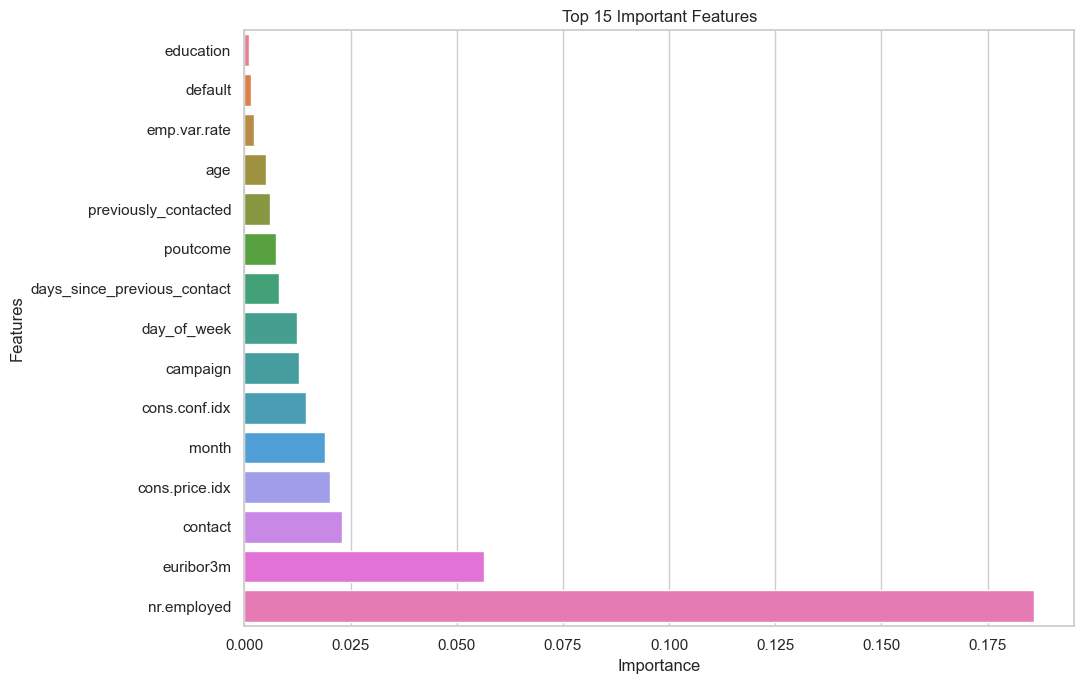

In [67]:
top_features = feature_importance_df.head(15).sort_values(
    by="Importance",
    ascending=True
)

plt.figure(figsize=(11, 7))

sns.barplot(
    data=top_features,
    x="Importance",
    y="Feature",
    hue="Feature",
    legend=False
)

plt.title("Top 15 Important Features")
plt.xlabel("Importance")
plt.ylabel("Features")

plt.tight_layout()
plt.show()

## Step 13: Model Saving

The selected machine learning pipeline is saved using Joblib.

The saved pipeline includes feature preprocessing and the
trained classification model.

In [68]:
import joblib
from pathlib import Path

# Create models directory
models_dir = Path("models")
models_dir.mkdir(exist_ok=True)

# Save complete pipeline
model_path = models_dir / "portuguese_bank_model.pkl"

joblib.dump(tuned_candidate, model_path)

print("Model saved successfully!")
print("Model location:", model_path.resolve())

Model saved successfully!
Model location: C:\Users\prana\Project For ML\PRCP-1000-PortugeseBank\models\portuguese_bank_model.pkl


In [69]:
# Load saved model
loaded_model = joblib.load(model_path)

print("Saved model loaded successfully!")

# Test predictions
sample_predictions = loaded_model.predict(X_test.iloc[:10])

sample_probabilities = loaded_model.predict_proba(
    X_test.iloc[:10]
)[:, 1]

test_results = pd.DataFrame({
    "Actual": y_test.iloc[:10].values,
    "Predicted": sample_predictions,
    "Subscription Probability": sample_probabilities.round(4)
})

display(test_results)

Saved model loaded successfully!


,Actual,Predicted,Subscription Probability
0,0,0,0.0222
1,1,1,0.7337
2,0,0,0.0948
3,0,0,0.1294
4,0,0,0.0570
5,0,0,0.0454
6,0,0,0.0979
7,0,0,0.0608
8,0,0,0.0807
9,0,0,0.0550


## Step 15: Business Recommendations

Based on the Portuguese Bank Marketing analysis, the bank
marketing team can consider the following strategies.

### 1. Customer Segmentation
Segment customers based on demographic information,
previous campaign history, and economic indicators.

### 2. Targeted Marketing
Use the predictive model to identify customers with a
higher probability of subscribing to term deposits.

### 3. Previous Campaign Performance
Analyze previous campaign outcomes and prioritize
appropriate follow-up strategies.

### 4. Contact Strategy
Evaluate campaign contact frequency and avoid repeatedly
contacting customers without considering previous responses.

### 5. Communication Channels
Compare the effectiveness of cellular and telephone
communication channels.

### 6. Campaign Timing
Analyze subscription patterns across different months
and weekdays to improve campaign scheduling.

### 7. Model-Based Customer Prioritization
Use prediction probabilities to create customer priority
groups for marketing campaigns.

### 8. Continuous Model Monitoring
Monitor precision, recall, subscription conversion rates,
and model performance as new campaign data becomes available.

### Business Recommendation Conclusion

The bank should use data-driven customer segmentation and
predictive modeling to improve marketing efficiency,
prioritize potential subscribers, and reduce unnecessary
marketing calls.

All recommendations should be validated through controlled
marketing experiments before full-scale implementation.

## Step 16: Challenges Faced and Solutions

| Challenge | Solution |
|---|---|
| Duplicate records | Removed exact duplicate rows |
| Unknown categorical values | Retained unknown as a separate category |
| Class imbalance | Used stratified splitting and evaluated precision, recall, F1 and PR-AUC |
| Categorical variables | Applied OneHotEncoder |
| Different numerical scales | Applied StandardScaler |
| Data leakage from duration | Excluded duration from production features |
| pdays sentinel value | Created previous-contact indicator and transformed the sentinel |
| Model selection | Compared multiple classification algorithms |
| Overfitting risk | Used cross-validation and regularized model configurations |
| Hyperparameter selection | Applied RandomizedSearchCV |
| Reproducibility | Used fixed random states and saved the complete pipeline |

### Conclusion

The project required careful data cleaning, feature engineering,
preprocessing, model comparison, and evaluation.

The selected techniques help build a reproducible predictive
model suitable for further business validation.

In [70]:

print("=" * 65)
print("PORTUGUESE BANK MARKETING — FINAL PROJECT SUMMARY")
print("=" * 65)

print("\n1. DATASET")
print("Dataset shape after cleaning:", df.shape)
print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

print("\n2. TARGET DISTRIBUTION")
print(df["y"].value_counts())
print("\nTarget percentages:")
print((df["y"].value_counts(normalize=True) * 100).round(2))

print("\n3. MODEL COMPARISON")
display(comparison_df)

print("\n4. CROSS-VALIDATION COMPARISON")
display(cv_comparison_df)

print("\n5. BEST MODEL")
print("Selected model:", best_model_name)
print("Best tuning parameters:", random_search.best_params_)
print("Best cross-validation PR-AUC:", round(random_search.best_score_, 4))

print("\n6. FINAL TEST RESULTS")
display(pd.DataFrame([final_metrics]))

print("\n7. THRESHOLD ANALYSIS")
display(threshold_df)

print("\n8. TOP 15 IMPORTANT FEATURES")
display(feature_importance_df.head(15))

print("\n9. SAVED MODEL")
print("Model path:", model_path)
print("Model exists:", model_path.exists())

print("\n" + "=" * 65)
print("END OF PROJECT SUMMARY")
print("=" * 65)


PORTUGUESE BANK MARKETING — FINAL PROJECT SUMMARY

1. DATASET
Dataset shape after cleaning: (41176, 21)
Training data shape: (32940, 20)
Testing data shape: (8236, 20)

2. TARGET DISTRIBUTION
y
no     36537
yes     4639
Name: count, dtype: int64

Target percentages:
y
no     88.73
yes    11.27
Name: proportion, dtype: float64

3. MODEL COMPARISON


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC,PR-AUC
0,HistGradientBoosting,0.900801,0.665672,0.240302,0.353127,0.814582,0.494705
1,Random Forest,0.874332,0.456112,0.599138,0.517932,0.810560,0.476622
2,Gradient Boosting,0.898130,0.650847,0.206897,0.313982,0.803785,0.475711
3,Extra Trees,0.860248,0.419726,0.628233,0.503237,0.806148,0.471674
4,Decision Tree,0.843371,0.379654,0.615302,0.469572,0.776881,0.448649
5,Logistic Regression,0.830379,0.359328,0.645474,0.461657,0.800137,0.445977



4. CROSS-VALIDATION COMPARISON


,Model,CV Accuracy,CV Precision,CV Recall,CV F1,CV ROC-AUC,CV PR-AUC
0,HistGradientBoosting,0.900971,0.665666,0.244139,0.357099,0.801559,0.467381
1,Gradient Boosting,0.901245,0.683102,0.230933,0.345075,0.793696,0.461943
2,Random Forest,0.871099,0.443307,0.560226,0.494848,0.795929,0.454180
3,Extra Trees,0.853855,0.399161,0.586635,0.474993,0.791903,0.448833
4,Logistic Regression,0.828719,0.352640,0.622201,0.450108,0.790563,0.445806
5,Decision Tree,0.838282,0.365643,0.589872,0.451131,0.760012,0.415510



5. BEST MODEL
Selected model: HistGradientBoosting
Best tuning parameters: {'classifier__max_leaf_nodes': 15, 'classifier__max_iter': 150, 'classifier__learning_rate': 0.03, 'classifier__l2_regularization': 0.1}
Best cross-validation PR-AUC: 0.4678

6. FINAL TEST RESULTS


,Accuracy,Precision,Recall,F1 Score,ROC-AUC,PR-AUC
0,0.900559,0.666667,0.234914,0.34741,0.813912,0.493269



7. THRESHOLD ANALYSIS


,Threshold,Precision,Recall,F1 Score
0,0.10,0.351023,0.684267,0.464012
1,0.15,0.439519,0.630388,0.517928
2,0.20,0.473109,0.606681,0.531634
3,0.25,0.487296,0.578664,0.529064
4,0.30,0.509290,0.502155,0.505697
5,0.35,0.551829,0.390086,0.457071
6,0.40,0.612159,0.314655,0.415658
7,0.45,0.645833,0.267241,0.378049
8,0.50,0.666667,0.234914,0.347410
9,0.55,0.704981,0.198276,0.309504



8. TOP 15 IMPORTANT FEATURES


,Feature,Importance,Std
0,nr.employed,0.186038,0.011221
1,euribor3m,0.056420,0.005041
2,contact,0.022873,0.003237
3,cons.price.idx,0.020131,0.001631
4,month,0.019100,0.003486
5,cons.conf.idx,0.014480,0.002237
6,campaign,0.012973,0.001179
7,day_of_week,0.012279,0.002269
8,days_since_previous_contact,0.008147,0.001833
9,poutcome,0.007450,0.003026



9. SAVED MODEL
Model path: models\portuguese_bank_model.pkl
Model exists: True

END OF PROJECT SUMMARY


In [71]:

from sklearn.model_selection import cross_val_predict, StratifiedKFold
from sklearn.metrics import precision_recall_curve, f1_score
import numpy as np
import pandas as pd

# Generate out-of-fold probabilities using training data only
threshold_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

oof_probabilities = cross_val_predict(
    tuned_candidate,
    X_train,
    y_train,
    cv=threshold_cv,
    method="predict_proba",
    n_jobs=-1
)[:, 1]

# Find the threshold with the best training out-of-fold F1
precision_values, recall_values, thresholds = precision_recall_curve(
    y_train,
    oof_probabilities
)

f1_values = (
    2 * precision_values[:-1] * recall_values[:-1]
    / (precision_values[:-1] + recall_values[:-1] + 1e-10)
)

best_index = np.argmax(f1_values)
production_threshold = float(thresholds[best_index])

print("Selected threshold:", round(production_threshold, 4))
print("Out-of-fold precision:", round(precision_values[best_index], 4))
print("Out-of-fold recall:", round(recall_values[best_index], 4))
print("Out-of-fold F1:", round(f1_values[best_index], 4))


Selected threshold: 0.2145
Out-of-fold precision: 0.4495
Out-of-fold recall: 0.5621
Out-of-fold F1: 0.4995


In [72]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report
)

# Predict using the selected threshold
final_test_probabilities = tuned_candidate.predict_proba(X_test)[:, 1]

final_test_predictions = (
    final_test_probabilities >= production_threshold
).astype(int)

# Calculate final test metrics
production_metrics = {
    "Threshold": production_threshold,
    "Accuracy": accuracy_score(y_test, final_test_predictions),
    "Precision": precision_score(y_test, final_test_predictions, zero_division=0),
    "Recall": recall_score(y_test, final_test_predictions, zero_division=0),
    "F1 Score": f1_score(y_test, final_test_predictions, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, final_test_probabilities),
    "PR-AUC": average_precision_score(y_test, final_test_probabilities)
}

display(pd.DataFrame([production_metrics]))

print("Confusion Matrix:")
print(confusion_matrix(y_test, final_test_predictions))

print("\nClassification Report:")
print(classification_report(
    y_test,
    final_test_predictions,
    target_names=["No Subscription", "Subscription"]
))


,Threshold,Accuracy,Precision,Recall,F1 Score,ROC-AUC,PR-AUC
0,0.214548,0.880646,0.476273,0.594828,0.528989,0.813912,0.493269


Confusion Matrix:
[[6701  607]
 [ 376  552]]

Classification Report:
                 precision    recall  f1-score   support

No Subscription       0.95      0.92      0.93      7308
   Subscription       0.48      0.59      0.53       928

       accuracy                           0.88      8236
      macro avg       0.71      0.76      0.73      8236
   weighted avg       0.89      0.88      0.89      8236



In [73]:

print("SELECTED PRODUCTION THRESHOLD:", production_threshold)
print("\nFINAL PRODUCTION METRICS:")
display(pd.DataFrame([production_metrics]))

print("\nCONFUSION MATRIX:")
print(confusion_matrix(y_test, final_test_predictions))

print("\nMODEL FILE EXISTS:", model_path.exists())


SELECTED PRODUCTION THRESHOLD: 0.2145478737892797

FINAL PRODUCTION METRICS:


,Threshold,Accuracy,Precision,Recall,F1 Score,ROC-AUC,PR-AUC
0,0.214548,0.880646,0.476273,0.594828,0.528989,0.813912,0.493269



CONFUSION MATRIX:
[[6701  607]
 [ 376  552]]

MODEL FILE EXISTS: True


In [74]:

import joblib
from pathlib import Path

# Create final model package
final_model_package = {
    "model": tuned_candidate,
    "threshold": production_threshold,
    "features": X.columns.tolist(),
    "target_mapping": {
        0: "No Subscription",
        1: "Subscription"
    }
}

# Save final package
final_model_path = Path("models") / "portuguese_bank_final_model.pkl"

joblib.dump(final_model_package, final_model_path)

print("Final model saved successfully!")
print("File:", final_model_path)
print("File exists:", final_model_path.exists())


Final model saved successfully!
File: models\portuguese_bank_final_model.pkl
File exists: True


In [75]:

# Load saved model package
loaded_package = joblib.load(final_model_path)

loaded_model = loaded_package["model"]
loaded_threshold = loaded_package["threshold"]

# Predict using saved model
sample_data = X_test.iloc[:5]

sample_probabilities = loaded_model.predict_proba(sample_data)[:, 1]

sample_predictions = (
    sample_probabilities >= loaded_threshold
).astype(int)

sample_output = pd.DataFrame({
    "Actual": y_test.iloc[:5].map({
        0: "No Subscription",
        1: "Subscription"
    }).values,
    "Predicted": pd.Series(sample_predictions).map({
        0: "No Subscription",
        1: "Subscription"
    }).values,
    "Subscription Probability": sample_probabilities.round(4)
})

display(sample_output)


,Actual,Predicted,Subscription Probability
0,No Subscription,No Subscription,0.0222
1,Subscription,Subscription,0.7337
2,No Subscription,No Subscription,0.0948
3,No Subscription,No Subscription,0.1294
4,No Subscription,No Subscription,0.0570
